# Reproduce the main-folder paper figures — Λ = 300 MeV

This notebook recomputes **your QMM energy functional**, with the nuclear constraints stated in `main_revised.tex`. It uses the figures in `Effects_of_Nuclear_Incompressibility_on_Quarkyonic_Neutron_Stars/` and does not use `old_stuff/`.

The previous notebook assumed `equal_b` and repeated the **vdW excluded-volume** reference in every panel. Here the default is **`target_l`**, enforcing **J = 32.5 MeV and L = 58.9 MeV**, and each excluded-volume family gets its own **vdW attraction** reference. The Dieterici attraction uses the manuscript's species-density powers, with couplings converted to preserve the same saturation, J and L constraints. K₀ = 220, 300 MeV; n₀ = 0.16 fm⁻³; binding = −16 MeV; mN = 938 MeV. References have their own predicted K₀.

The calculations are not fitted to pixels. Without original numerical tables/settings, agreement with each supplied image must be measured, not assumed. See `AUDIT.md` in the output folder for findings and remaining discrepancies.

Run cells in order. Density and stellar checkpoints make reruns resumable. **This is a CPU calculation; opening the notebook does not run it.**

In [1]:
from pathlib import Path
import sys, os, tempfile
os.environ.setdefault('MPLCONFIGDIR',str(Path(tempfile.gettempdir())/'qmm_paper_reproduction_mpl'))
candidates=[q for p in [Path.cwd(),*Path.cwd().parents] for q in (p,p/'good_repo/QMM')]
ROOT=next(p.resolve() for p in candidates if (p/'scripts/reproduce_incompressibility_paper.py').exists())
sys.path[:0]=[str(ROOT/'src'),str(ROOT/'scripts')]
import qmm
assert Path(qmm.__file__).resolve().is_relative_to(ROOT), 'Restart kernel: a different QMM copy is imported.'
import reproduce_incompressibility_paper as rep
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown
print('Using',qmm.__file__)


Using /Users/dajuarez4/Documents/QuarkMatt/good_repo/QMM/src/qmm/__init__.py


## Controls and calibrations

Change `branch` to `equal_b` only for an explicitly labeled sensitivity study. That branch predicts L instead of reproducing 58.9 MeV. Keep Λ at 300 MeV for this comparison. The source files and full controls are hashed into each run directory, preventing reuse of incompatible checkpoints.

The default 0.004 fm⁻³ grid is followed by an independently solved 0.002 fm⁻³ grid around every sound-speed peak. For a full density-convergence rerun, set `density_step=0.002` and use a separate output directory; compare `validation_summary.csv`.

In [2]:
CONTROLS={**rep.DEFAULTS}
OUT=ROOT/'results/generated/paper_replication_lambda300'
PAPER=rep.DEFAULT_PAPER
COMPUTE_STARS=True
COMPUTE_TIDES=True
CHECK_PEAK_RESOLUTION=True
jobs=rep.make_jobs(OUT,CONTROLS)
parameters=pd.read_csv(OUT/'parameters.csv')
display(parameters[['family','ev','requested_K0','K0','J','L','a_n','a_pn','b_n','b_pn','parameter_value']])


,family,ev,requested_K0,K0,J,L,a_n,a_pn,b_n,b_pn,parameter_value
0,dieterici,tvm,220.0,220.000000,32.5,58.9,57.346906,106.824971,1.681358,3.323316,1.665593
1,dieterici,tvm,300.0,300.000000,32.5,58.9,82.024899,165.397055,1.978691,4.121078,1.755945
2,clausius,tvm,220.0,220.000001,32.5,58.9,269.302031,711.912476,1.268725,1.940129,5.320417
3,clausius,tvm,300.0,300.000001,32.5,58.9,242.009090,632.894805,1.628783,3.167425,3.371119
4,reference,tvm,NaN,564.221282,32.5,58.9,203.027112,494.991541,2.783095,5.777173,NaN
5,dieterici,cs,220.0,220.000005,32.5,58.9,57.375577,106.205324,1.765105,3.495041,1.664319
6,dieterici,cs,300.0,300.000000,32.5,58.9,80.591938,160.474844,2.066548,4.274784,1.749756
7,clausius,cs,220.0,220.000001,32.5,58.9,269.914067,711.334003,1.331907,2.064909,5.286776
8,clausius,cs,300.0,300.000000,32.5,58.9,243.531401,634.206550,1.709786,3.335265,3.385153
9,reference,cs,NaN,601.449391,32.5,58.9,204.151154,489.883285,2.936566,5.916863,NaN


## The Dieterici mismatch in the original code

The body of `main_revised.tex` defines $v_i=-\sum_j a_{ij}n_j^{\alpha-1}/(\alpha-1)$. Summing $n_i v_i$ gives

$$\epsilon_{\rm att}^{D}=-\frac{a_n(n_p^\alpha+n_n^\alpha)+a_{pn}(n_p n_n^{\alpha-1}+n_n n_p^{\alpha-1})}{\alpha-1}.$$

QMM previously used $-a_{\rm eff}(Y)n_H^\alpha/(\alpha-1)$, with a quadratic $a_{\rm eff}$. These agree at $\alpha=2$; at the fitted $\alpha<2$ they have different composition derivatives and beta equilibria. The paper's appendix repeats the quadratic form, so it conflicts with the body. Direct comparison to the PNGs favors the **species-power form**.

To preserve the nuclear calibration exactly, use $\bar a_{\rm paper}=2^{\alpha-2}\bar a_{\rm QMM}$, keep $a_n,b_n,b_{pn}$, and set $a_{pn}=2\bar a_{\rm paper}-a_n$. This preserves the symmetric- and pure-neutron energies at every density, and therefore preserves binding, K₀, J and L. The intermediate charge fractions change. The output parameter table contains the converted couplings. Set `dieterici_attraction='qmm'` only for an explicitly labeled comparison with the old energy functional.

## Beta equilibrium, conservation, and the energy minimum

`PaperEOS` extends your `AsymmetricQuarkyonicEOS`. The kinetic energies, shell construction, volume fractions and Clausius attraction are inherited. **For Dieterici, the paper's species-power interaction replaces QMM's different total-density-power extension.** It replaces repeated Simpson integrals with their analytic values and verifies the analytic composition derivative against finite differences of the original energy. The quark fraction is **scanned first**, and every finite local minimum is refined before choosing the lowest total energy. Every charge-neutral beta root found in the composition scan competes by total energy.

Here `n_u,n_d` are **quark number densities** (including color):

$$n_B=n_p+n_n+(n_u+n_d)/3,\quad \rho_Q=n_p+(2n_u-n_d)/3=Yn_B=n_e+n_\mu.$$

The manuscript also uses baryon-normalized quark densities in places; in that convention the same charge is $n_p+2n_u^B-n_d^B$. Mixing these conventions introduces a factor of three.

$$\mu_e=\mu_\mu=-\frac1{n_B}\left(\frac{\partial\epsilon_{HQ}}{\partial Y}\right)_{n_B,f_Q}.$$

The derivative must include the Y dependence of the inner shell momentum and both available-volume fractions. Lepton energy is included in the total energy minimized over $f_Q$. The exported `beta_residual_fd_mev` checks this relation using a separate finite difference. All units in the EOS tables are MeV and fm.

In [3]:
for job in jobs:
    rep.compute_eos(job)
    if CHECK_PEAK_RESOLUTION:
        rep.check_peak_resolution(job)
display(rep.summaries(jobs,OUT))


,model,K0_MeV,points,max_charge_residual_fm3,max_baryon_residual_fm3,max_beta_residual_fd_mev,minimum_vs2,maximum_vs2,coarse_density_step_fm3,fine_density_step_fm3,coarse_peak_cs2,coarse_peak_density_fm3,fine_peak_cs2,fine_peak_density_fm3,peak_relative_change,fine_peak_at_scan_edge,maximum_mass_msun,radius_at_maximum_mass_km,radius_at_1p4_msun_km,maximum_at_eos_boundary,crust_transition_energy_mev_fm3,crust_transition_pressure_mev_fm3,removed_above_crust_rows,warnings
0,dieterici_tvm,220.0,367,2.131854e-13,8.881784e-16,7.496657e-07,0.001214,0.625245,0.004,0.002,0.625245,0.604,0.625255,0.606,1.612059e-05,False,2.212742,11.344994,12.164990,False,74.535875,0.398374,0,[]
1,dieterici_tvm,300.0,367,2.040260e-13,1.332268e-15,1.832996e-06,0.001504,0.576631,0.004,0.002,0.576631,0.524,0.576614,0.524,2.980138e-05,False,2.290347,11.943739,12.582259,False,84.532476,0.491947,0,[]
2,clausius_tvm,220.0,367,9.773085e-14,1.332268e-15,2.965997e-06,0.001464,0.692769,0.004,0.002,0.692769,0.788,0.692782,0.786,1.848042e-05,False,2.063346,10.494942,11.818022,False,70.721184,0.365204,0,[]
3,clausius_tvm,300.0,367,1.459492e-13,1.332268e-15,1.355306e-06,0.001757,0.597641,0.004,0.002,0.597641,0.620,0.597631,0.618,1.534935e-05,False,2.208146,11.469868,12.478731,False,79.950051,0.447877,0,[]
4,reference_tvm,NaN,367,1.619330e-13,1.332268e-15,2.378420e-06,0.002269,0.498150,0.004,0.002,0.498150,0.392,0.498127,0.392,4.586989e-05,False,2.418654,13.049834,13.325187,False,104.579242,0.708829,0,[]
5,dieterici_cs,220.0,367,6.617408e-13,1.776357e-15,8.520216e-07,0.001198,0.644021,0.004,0.002,0.644021,0.576,0.644002,0.576,2.995259e-05,False,2.255291,11.519110,12.212732,False,73.699162,0.390976,0,[]
6,dieterici_cs,300.0,367,1.622470e-12,1.332268e-15,1.901974e-04,0.001472,0.588667,0.004,0.002,0.588667,0.500,0.588667,0.502,5.280428e-08,False,2.330125,12.079956,12.632207,False,83.136871,0.478317,0,[]
7,clausius_cs,220.0,367,1.171806e-13,8.881784e-16,1.392817e-06,0.001459,0.720341,0.004,0.002,0.720341,0.752,0.720355,0.750,1.968728e-05,False,2.095996,10.616133,11.833538,False,70.606534,0.364229,0,[]
8,clausius_cs,300.0,367,2.658594e-13,1.332268e-15,9.193700e-07,0.001743,0.613992,0.004,0.002,0.613992,0.600,0.613995,0.602,4.643869e-06,False,2.237800,11.559771,12.504825,False,79.477142,0.443441,0,[]
9,reference_cs,NaN,367,2.308257e-12,1.776357e-15,4.424884e-05,0.002268,0.506713,0.004,0.002,0.506713,0.372,0.506671,0.372,8.181569e-05,False,2.462789,13.279672,13.429263,False,104.716939,0.710444,0,[]


## Pressure and equilibrium sound speed

Use **total** equilibrium energy density, including rest mass, electrons and muons:

$$\mu_B=\frac{d\epsilon_{\rm eq}}{dn_B},\quad P=n_B\mu_B-\epsilon_{\rm eq},\quad c_s^2=\frac{n_B\epsilon_{\rm eq}''}{\epsilon_{\rm eq}'}.$$

The derivatives follow the re-equilibrated path. Holding Y or fQ fixed instead computes a different response. Differentiating the strong-sector energy *along* the beta path omits a lepton contribution; it is not the same as the baryon chemical potential at fixed electric charge.

The output uses an interpolating cubic spline with **zero smoothing** and retains independent `numpy.gradient` estimates in `pressure_gradient` and `vs2_gradient`. The peak refinement solves new equilibrium states; a fixed wide moving window would flatten the sharp vdW peaks. No negative or superluminal sound speeds are clipped.

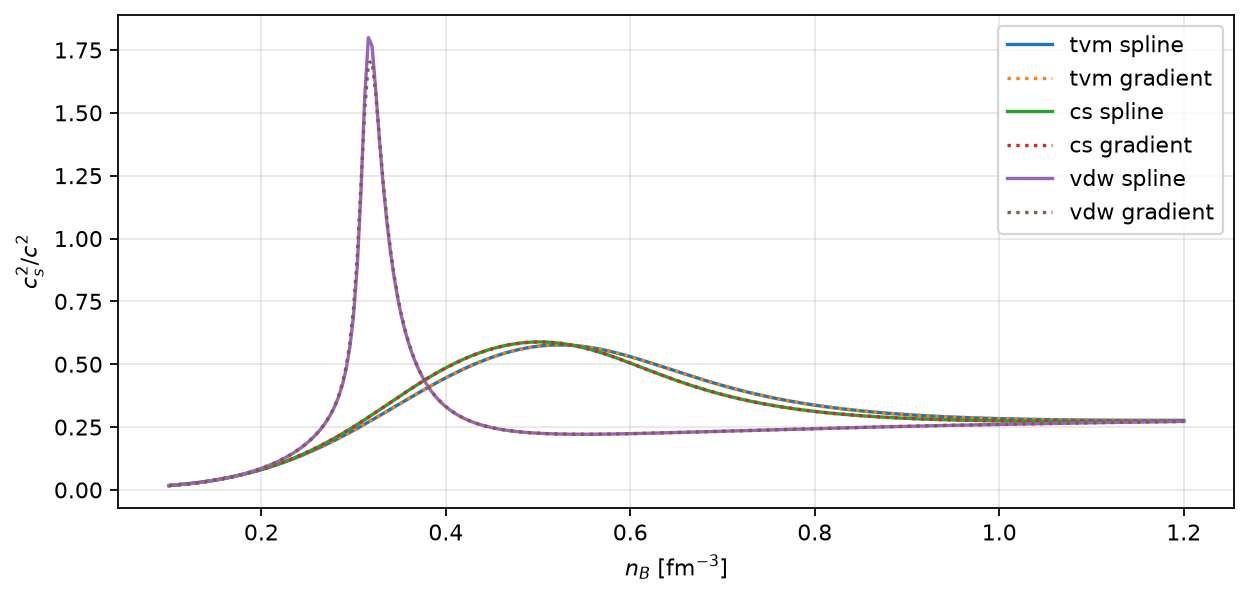

,model,K0_MeV,coarse_peak_cs2,fine_peak_cs2,peak_relative_change,max_beta_residual_fd_mev
0,dieterici_tvm,220.0,0.625245,0.625255,1.612059e-05,7.496657e-07
1,dieterici_tvm,300.0,0.576631,0.576614,2.980138e-05,1.832996e-06
2,clausius_tvm,220.0,0.692769,0.692782,1.848042e-05,2.965997e-06
3,clausius_tvm,300.0,0.597641,0.597631,1.534935e-05,1.355306e-06
4,reference_tvm,NaN,0.498150,0.498127,4.586989e-05,2.378420e-06
5,dieterici_cs,220.0,0.644021,0.644002,2.995259e-05,8.520216e-07
6,dieterici_cs,300.0,0.588667,0.588667,5.280428e-08,1.901974e-04
7,clausius_cs,220.0,0.720341,0.720355,1.968728e-05,1.392817e-06
8,clausius_cs,300.0,0.613992,0.613995,4.643869e-06,9.193700e-07
9,reference_cs,NaN,0.506713,0.506671,8.181569e-05,4.424884e-05


In [4]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(9,4))
for j in jobs:
    if j['family']=='dieterici' and j['k0']==300:
        f=j['eos'];p=f.n_b.between(.1,1.2)
        ax.plot(f.n_b[p],f.vs2[p],label=j['ev']+' spline')
        ax.plot(f.n_b[p],f.vs2_gradient[p],ls=':',label=j['ev']+' gradient')
ax.set(xlabel=r'$n_B$ [fm$^{-3}$]',ylabel=r'$c_s^2/c^2$');ax.legend();ax.grid(alpha=.3)
fig.savefig(OUT/'derivative_crosscheck.png',dpi=160,bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(OUT/'derivative_crosscheck.png')))
display(rep.summaries(jobs,OUT)[['model','K0_MeV','coarse_peak_cs2','fine_peak_cs2','peak_relative_change','max_beta_residual_fd_mev']])


## Crust, mass–radius, central composition and tides

Use the bundled BPS crust and QMM TOV/Love solver. The uniform core must be positive and strictly monotone above 0.04 fm⁻³; the notebook stops if a phase construction would be needed instead of deleting problematic core samples. The highest core–crust pressure crossing is recorded. TOV calculations retain the sequence beyond the mass maximum, matching the paper's presentation; the `stable_branch` flag identifies the ascending mass sequence.

Tidal failures and integration warnings are saved explicitly. Failed points appear as gaps. A finite density table cannot certify a maximum if the peak occurs at its upper boundary; inspect the metadata and extend `maximum_density` if necessary. Observational shaded bands are not redrawn because their source contour data are unavailable.

The TOV surface is located explicitly where pressure reaches the crust table minimum. This replaces the legacy post-surface mass-plateau heuristic and avoids integration through a discontinuous stopping rule.

In [5]:
if COMPUTE_STARS:
    for job in jobs:
        print('Stars:',job['key'],job['k0'],flush=True)
        rep.compute_stars(job,tides=COMPUTE_TIDES)
display(rep.summaries(jobs,OUT))


Stars: dieterici_tvm 220.0
Stars: dieterici_tvm 300.0
Stars: clausius_tvm 220.0
Stars: clausius_tvm 300.0
Stars: reference_tvm None
Stars: dieterici_cs 220.0
Stars: dieterici_cs 300.0
Stars: clausius_cs 220.0
Stars: clausius_cs 300.0
Stars: reference_cs None
Stars: dieterici_vdw 220.0
Stars: dieterici_vdw 300.0
Stars: clausius_vdw 220.0
Stars: clausius_vdw 300.0
Stars: reference_vdw None


,model,K0_MeV,points,max_charge_residual_fm3,max_baryon_residual_fm3,max_beta_residual_fd_mev,minimum_vs2,maximum_vs2,coarse_density_step_fm3,fine_density_step_fm3,coarse_peak_cs2,coarse_peak_density_fm3,fine_peak_cs2,fine_peak_density_fm3,peak_relative_change,fine_peak_at_scan_edge,maximum_mass_msun,radius_at_maximum_mass_km,radius_at_1p4_msun_km,maximum_at_eos_boundary,crust_transition_energy_mev_fm3,crust_transition_pressure_mev_fm3,removed_above_crust_rows,warnings,failed_tides
0,dieterici_tvm,220.0,367,2.131854e-13,8.881784e-16,7.496657e-07,0.001214,0.625245,0.004,0.002,0.625245,0.604,0.625255,0.606,1.612059e-05,False,2.212742,11.344994,12.164990,False,74.535875,0.398374,0,[],0
1,dieterici_tvm,300.0,367,2.040260e-13,1.332268e-15,1.832996e-06,0.001504,0.576631,0.004,0.002,0.576631,0.524,0.576614,0.524,2.980138e-05,False,2.290347,11.943739,12.582259,False,84.532476,0.491947,0,[],0
2,clausius_tvm,220.0,367,9.773085e-14,1.332268e-15,2.965997e-06,0.001464,0.692769,0.004,0.002,0.692769,0.788,0.692782,0.786,1.848042e-05,False,2.063346,10.494942,11.818022,False,70.721184,0.365204,0,[],0
3,clausius_tvm,300.0,367,1.459492e-13,1.332268e-15,1.355306e-06,0.001757,0.597641,0.004,0.002,0.597641,0.620,0.597631,0.618,1.534935e-05,False,2.208146,11.469868,12.478731,False,79.950051,0.447877,0,[],0
4,reference_tvm,NaN,367,1.619330e-13,1.332268e-15,2.378420e-06,0.002269,0.498150,0.004,0.002,0.498150,0.392,0.498127,0.392,4.586989e-05,False,2.418654,13.049834,13.325187,False,104.579242,0.708829,0,[],0
5,dieterici_cs,220.0,367,6.617408e-13,1.776357e-15,8.520216e-07,0.001198,0.644021,0.004,0.002,0.644021,0.576,0.644002,0.576,2.995259e-05,False,2.255291,11.519110,12.212732,False,73.699162,0.390976,0,[],0
6,dieterici_cs,300.0,367,1.622470e-12,1.332268e-15,1.901974e-04,0.001472,0.588667,0.004,0.002,0.588667,0.500,0.588667,0.502,5.280428e-08,False,2.330125,12.079956,12.632207,False,83.136871,0.478317,0,[],0
7,clausius_cs,220.0,367,1.171806e-13,8.881784e-16,1.392817e-06,0.001459,0.720341,0.004,0.002,0.720341,0.752,0.720355,0.750,1.968728e-05,False,2.095996,10.616133,11.833538,False,70.606534,0.364229,0,[],0
8,clausius_cs,300.0,367,2.658594e-13,1.332268e-15,9.193700e-07,0.001743,0.613992,0.004,0.002,0.613992,0.600,0.613995,0.602,4.643869e-06,False,2.237800,11.559771,12.504825,False,79.477142,0.443441,0,[],0
9,reference_cs,NaN,367,2.308257e-12,1.776357e-15,4.424884e-05,0.002268,0.506713,0.004,0.002,0.506713,0.372,0.506671,0.372,8.181569e-05,False,2.462789,13.279672,13.429263,False,104.716939,0.710444,0,[],0


## Recomputed figures and original images

The figure layouts follow the paper. PNG and PDF exports contain computed curves only. Original images below are for direct visual comparison; they are never substituted for calculated results.

Saved 32 files in /Users/dajuarez4/Documents/QuarkMatt/good_repo/QMM/results/generated/paper_replication_lambda300


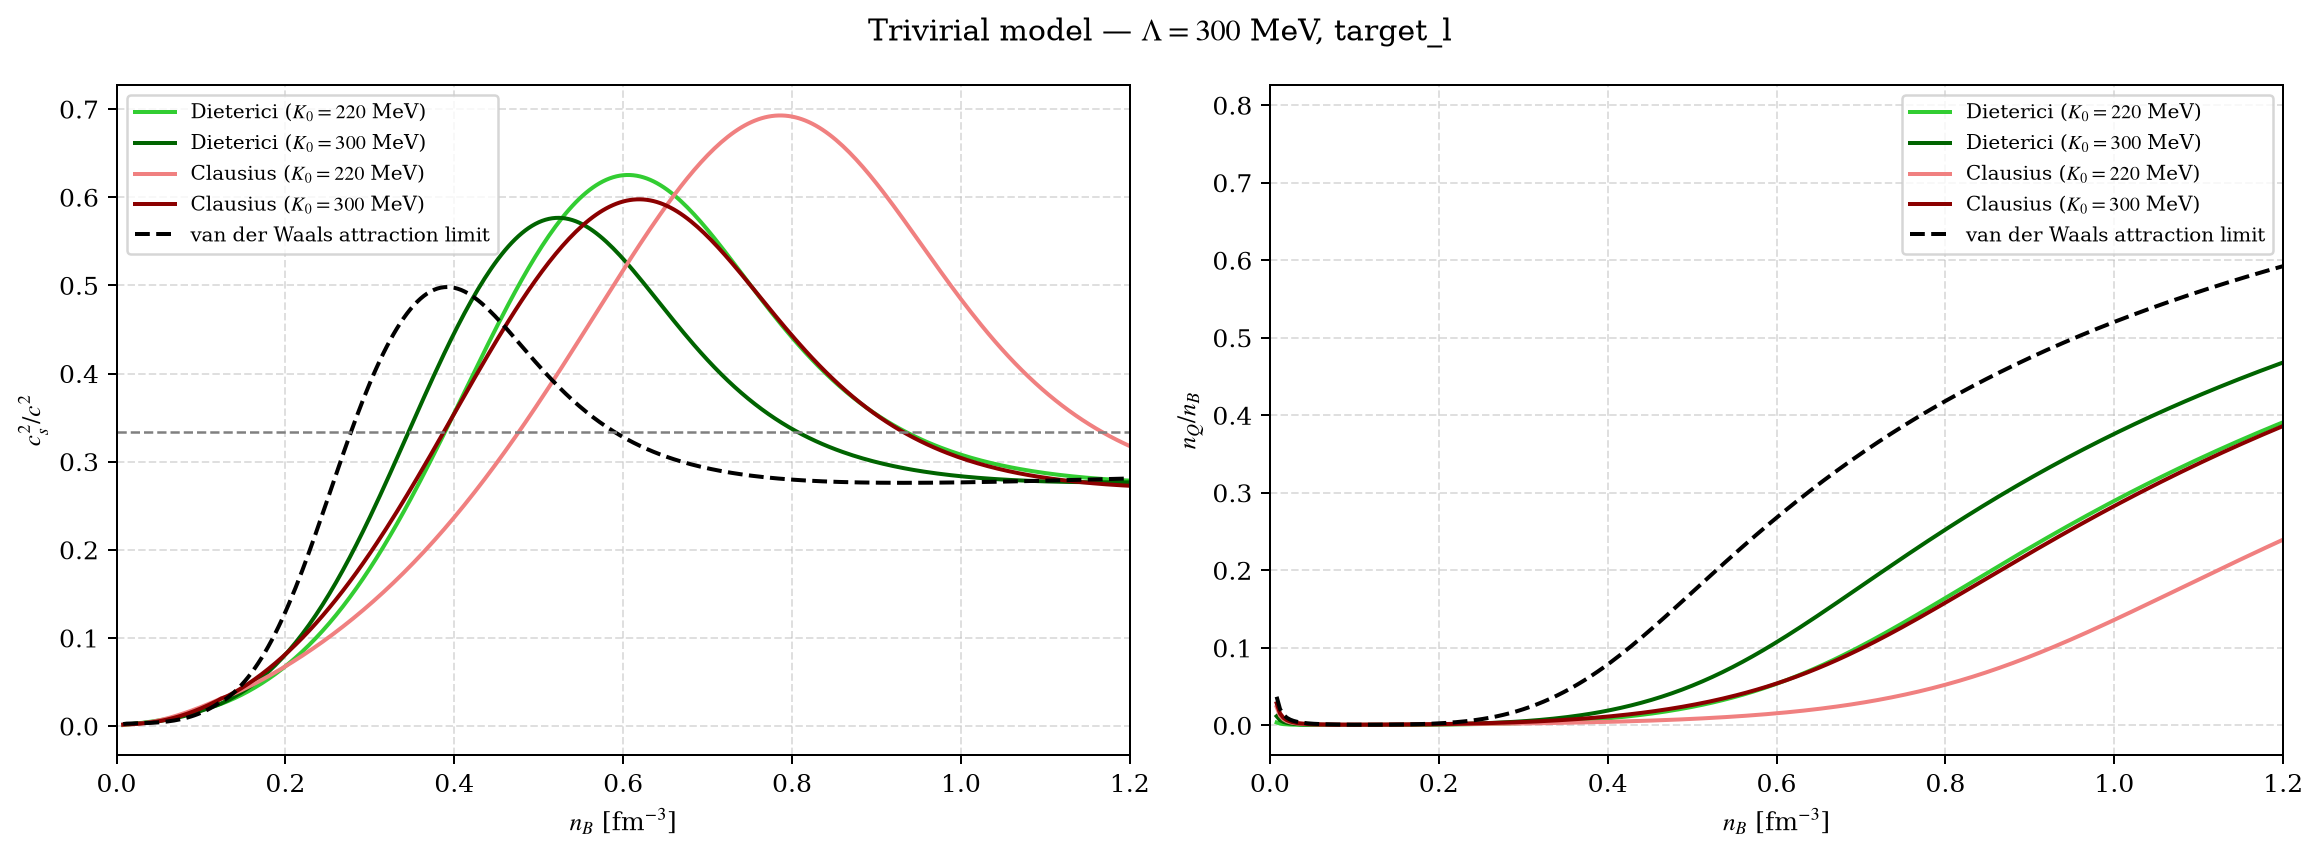

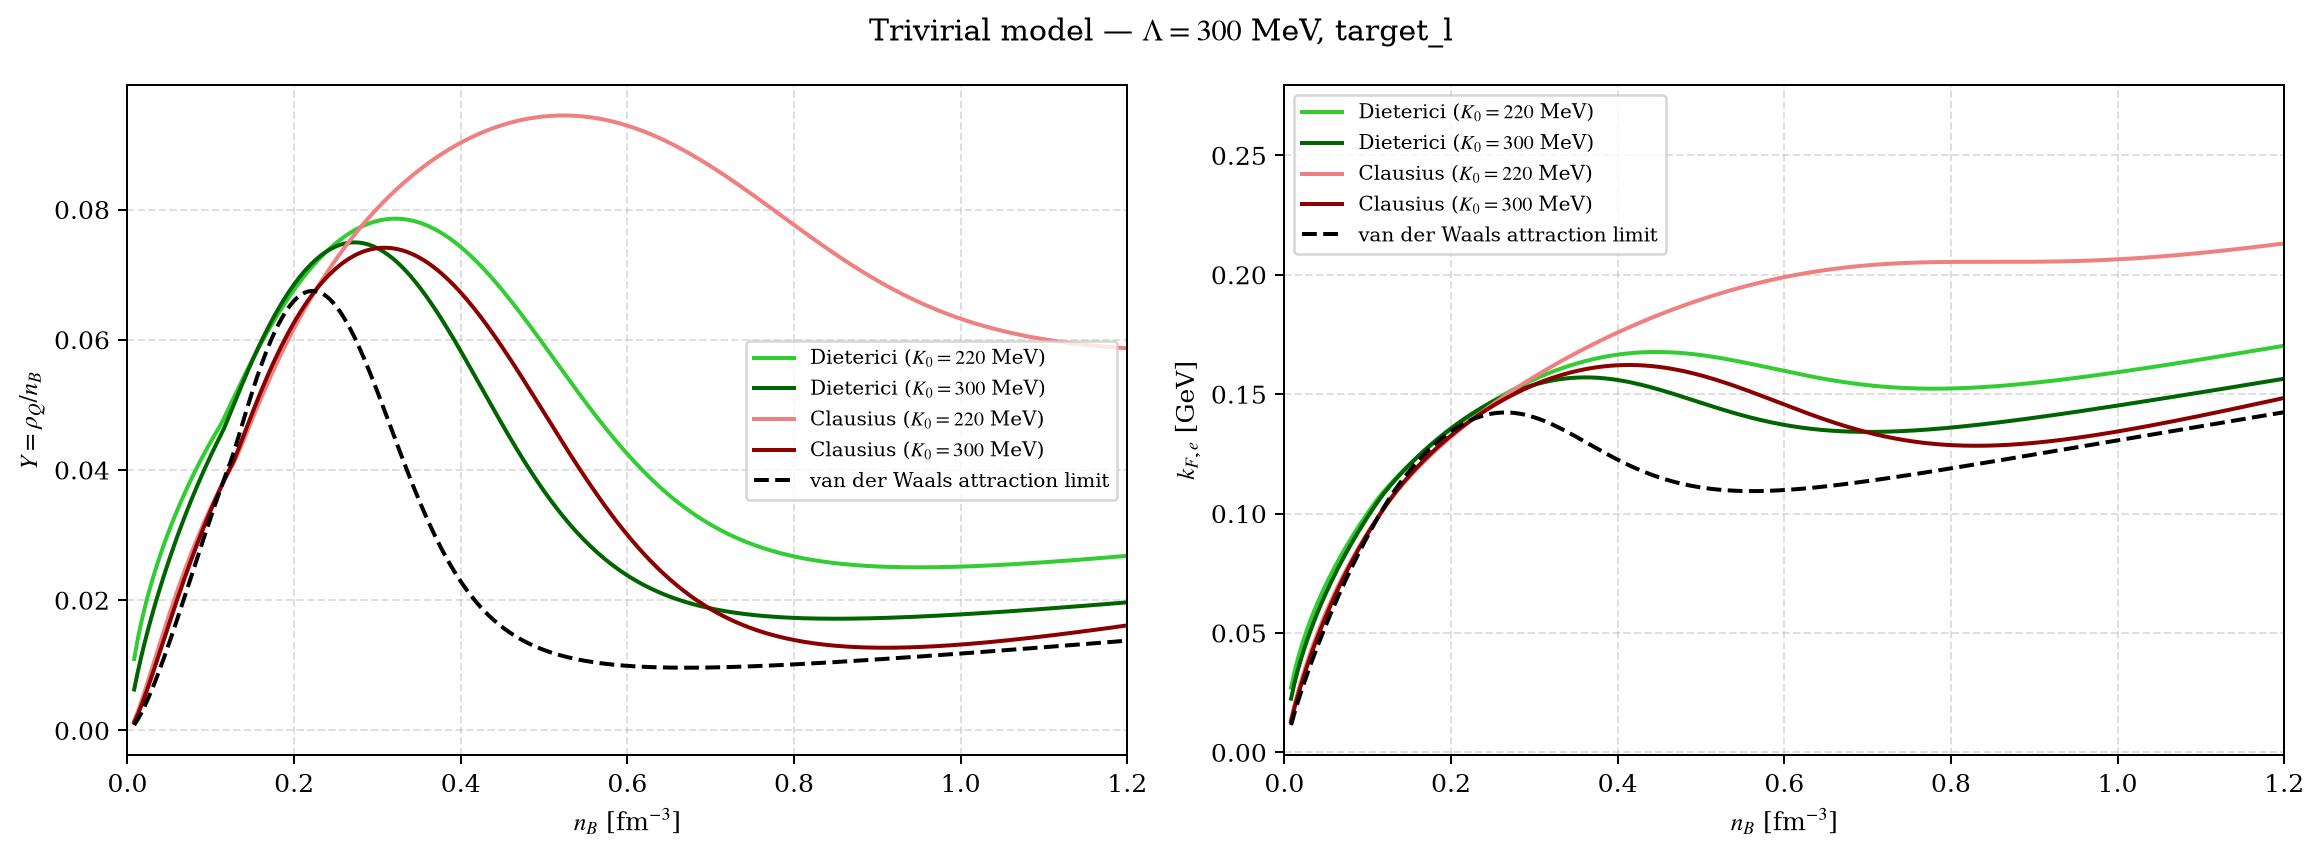

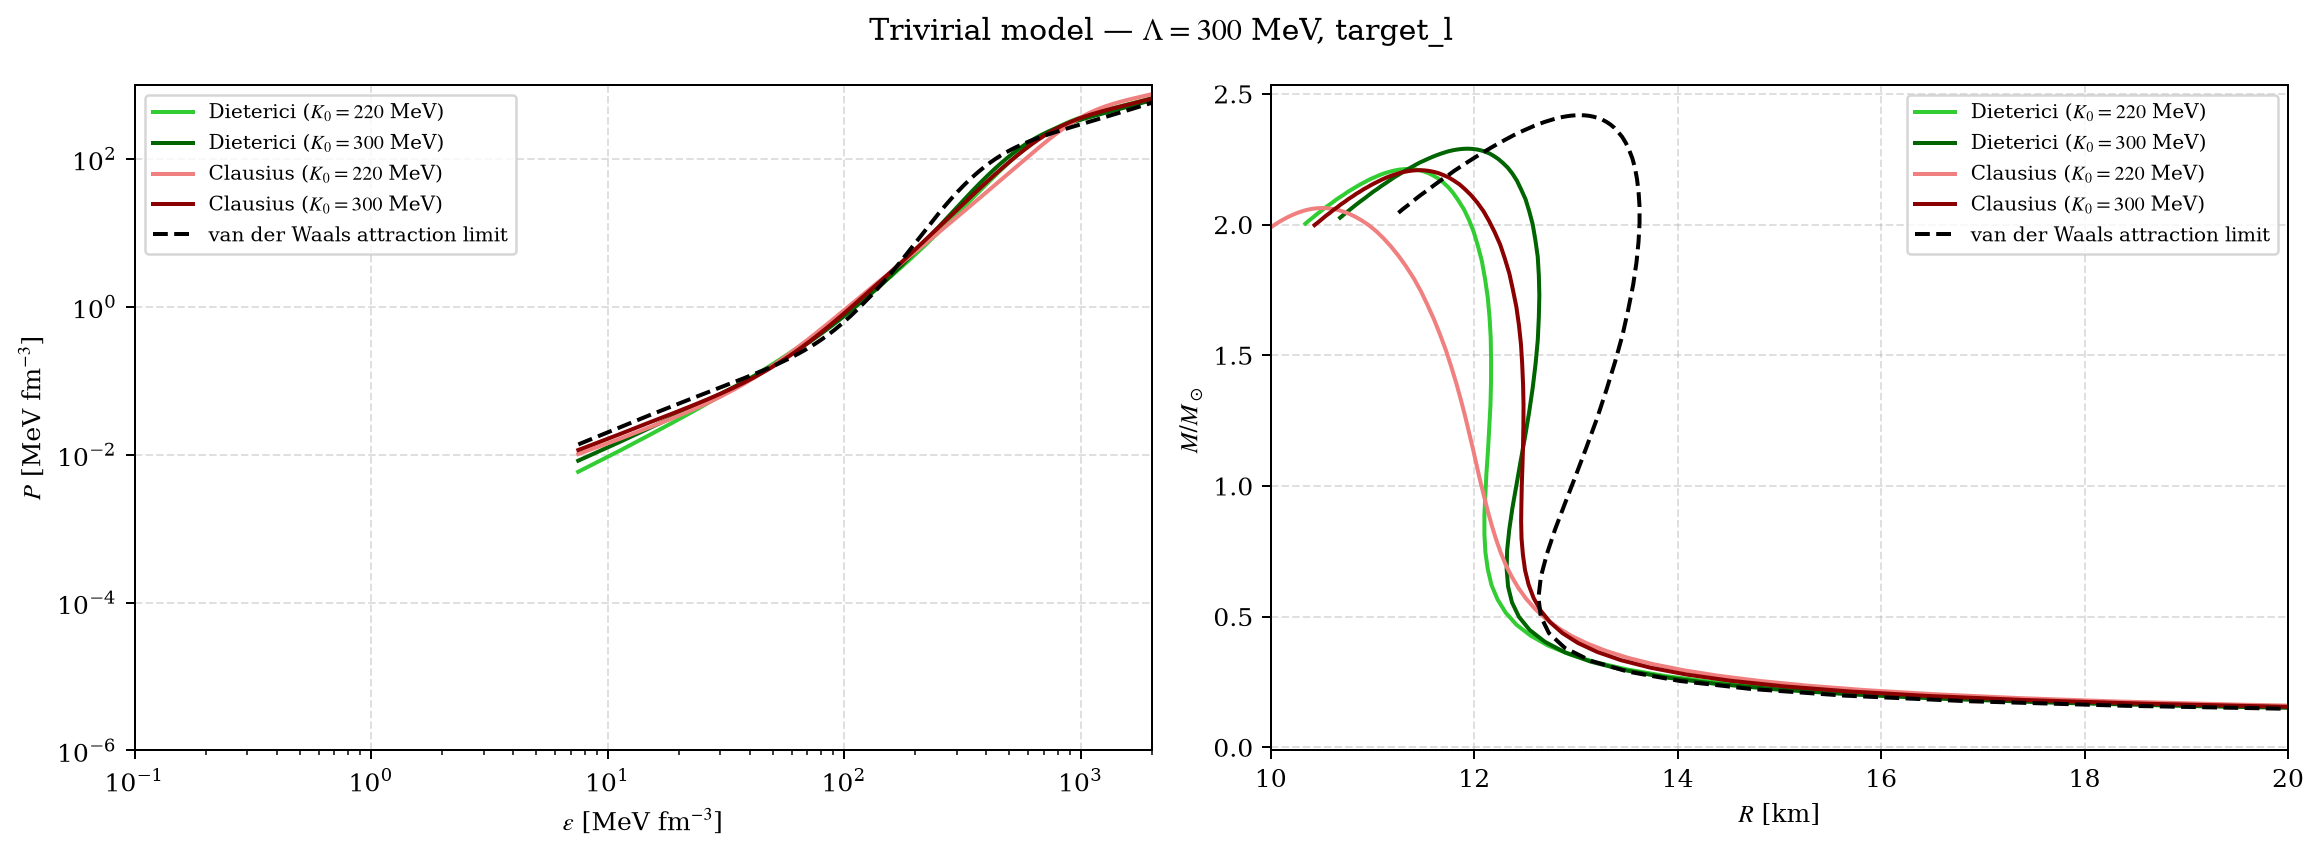

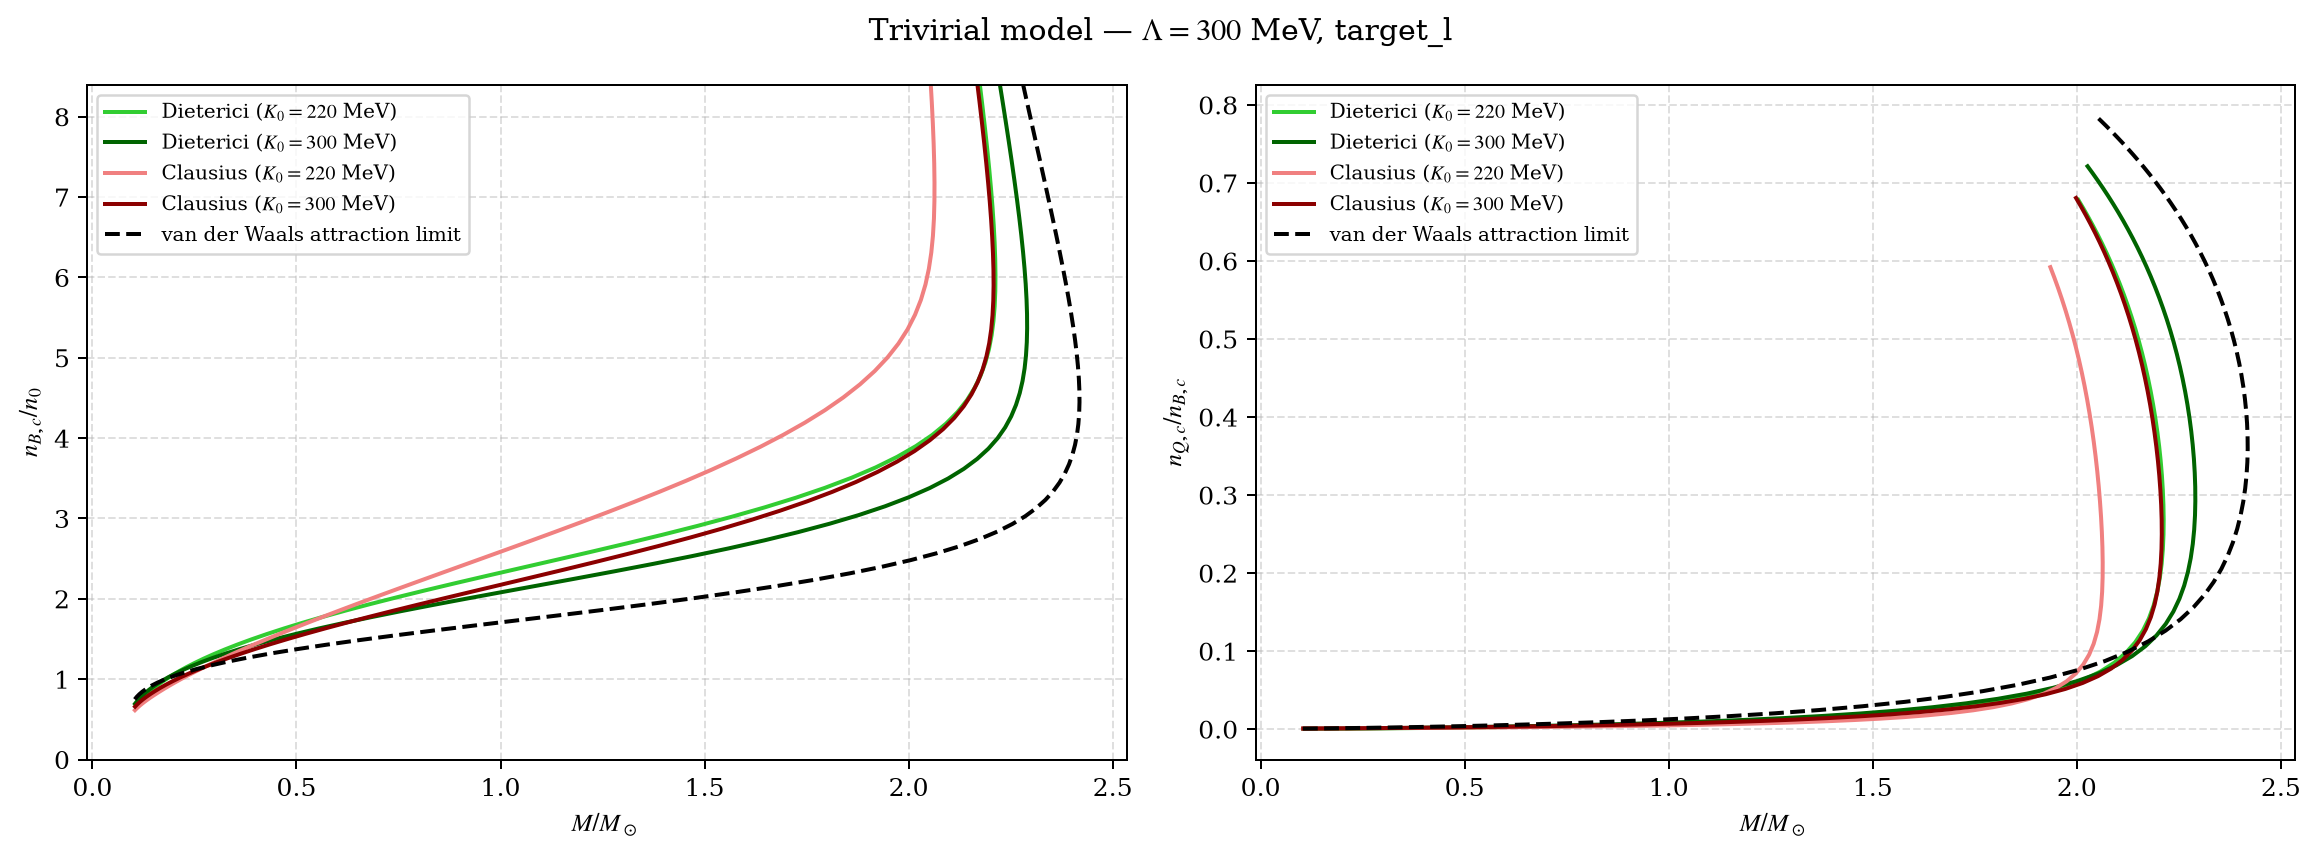

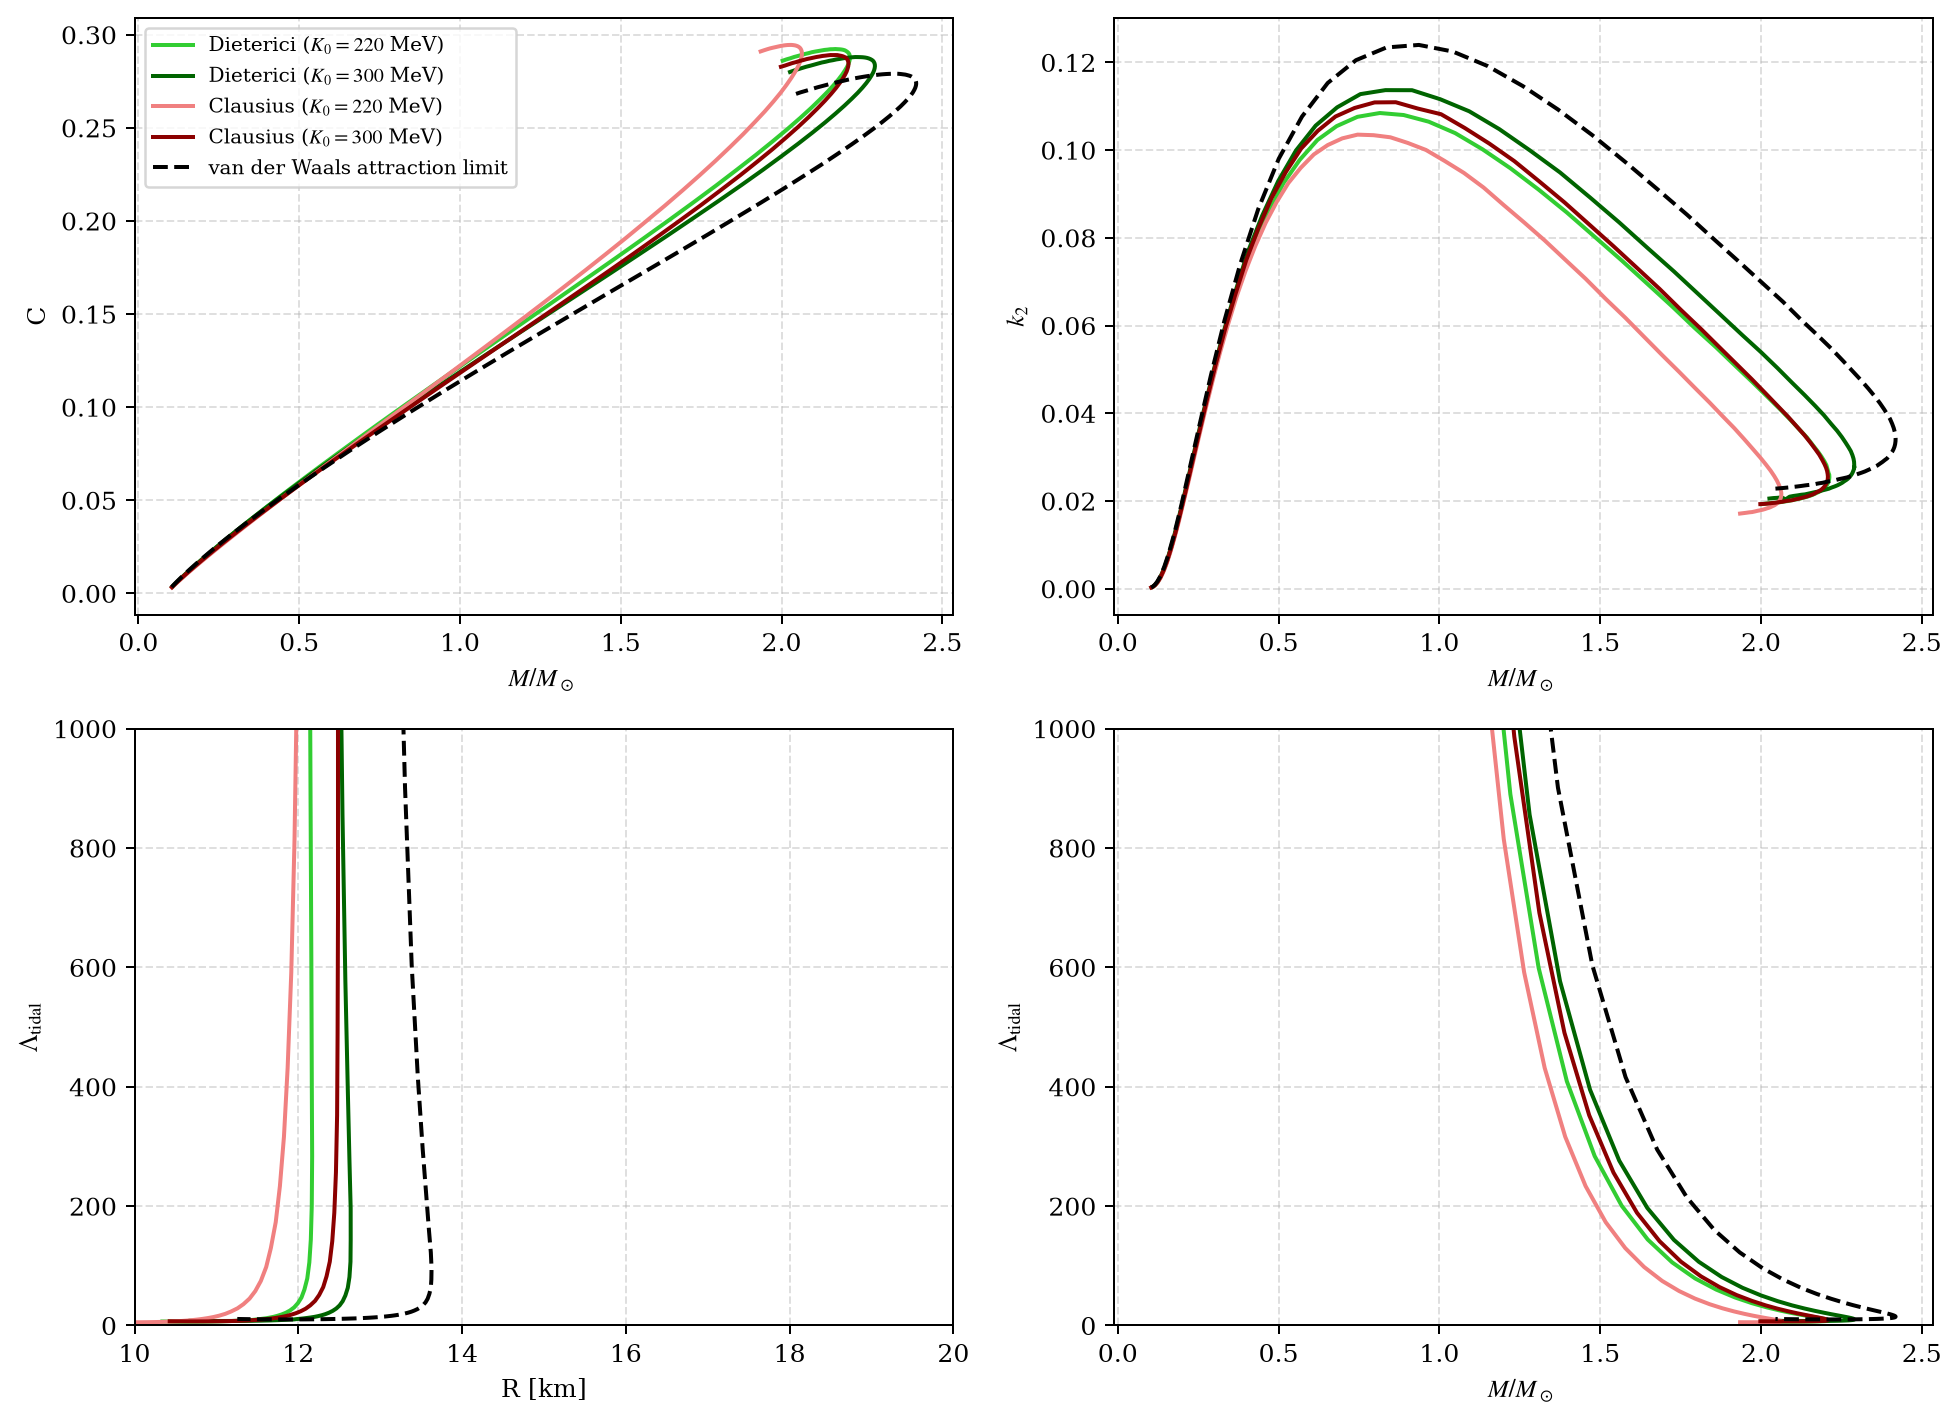

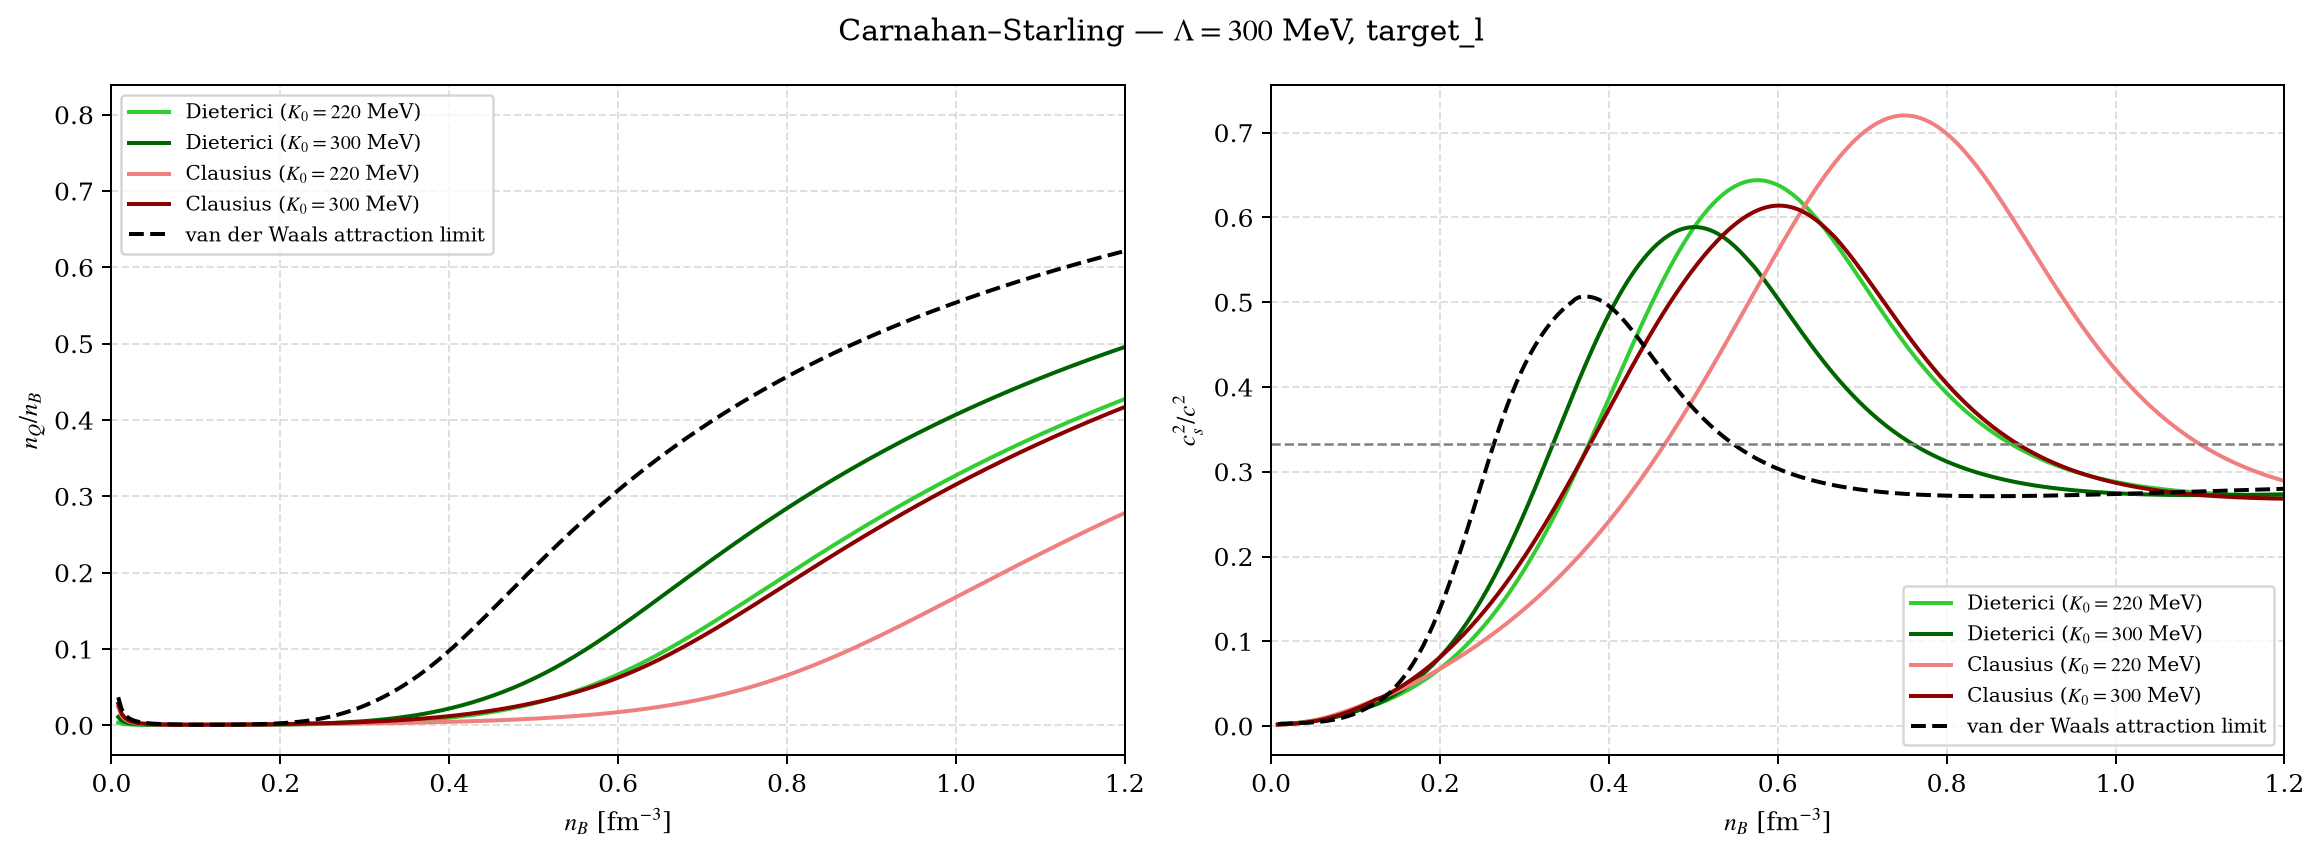

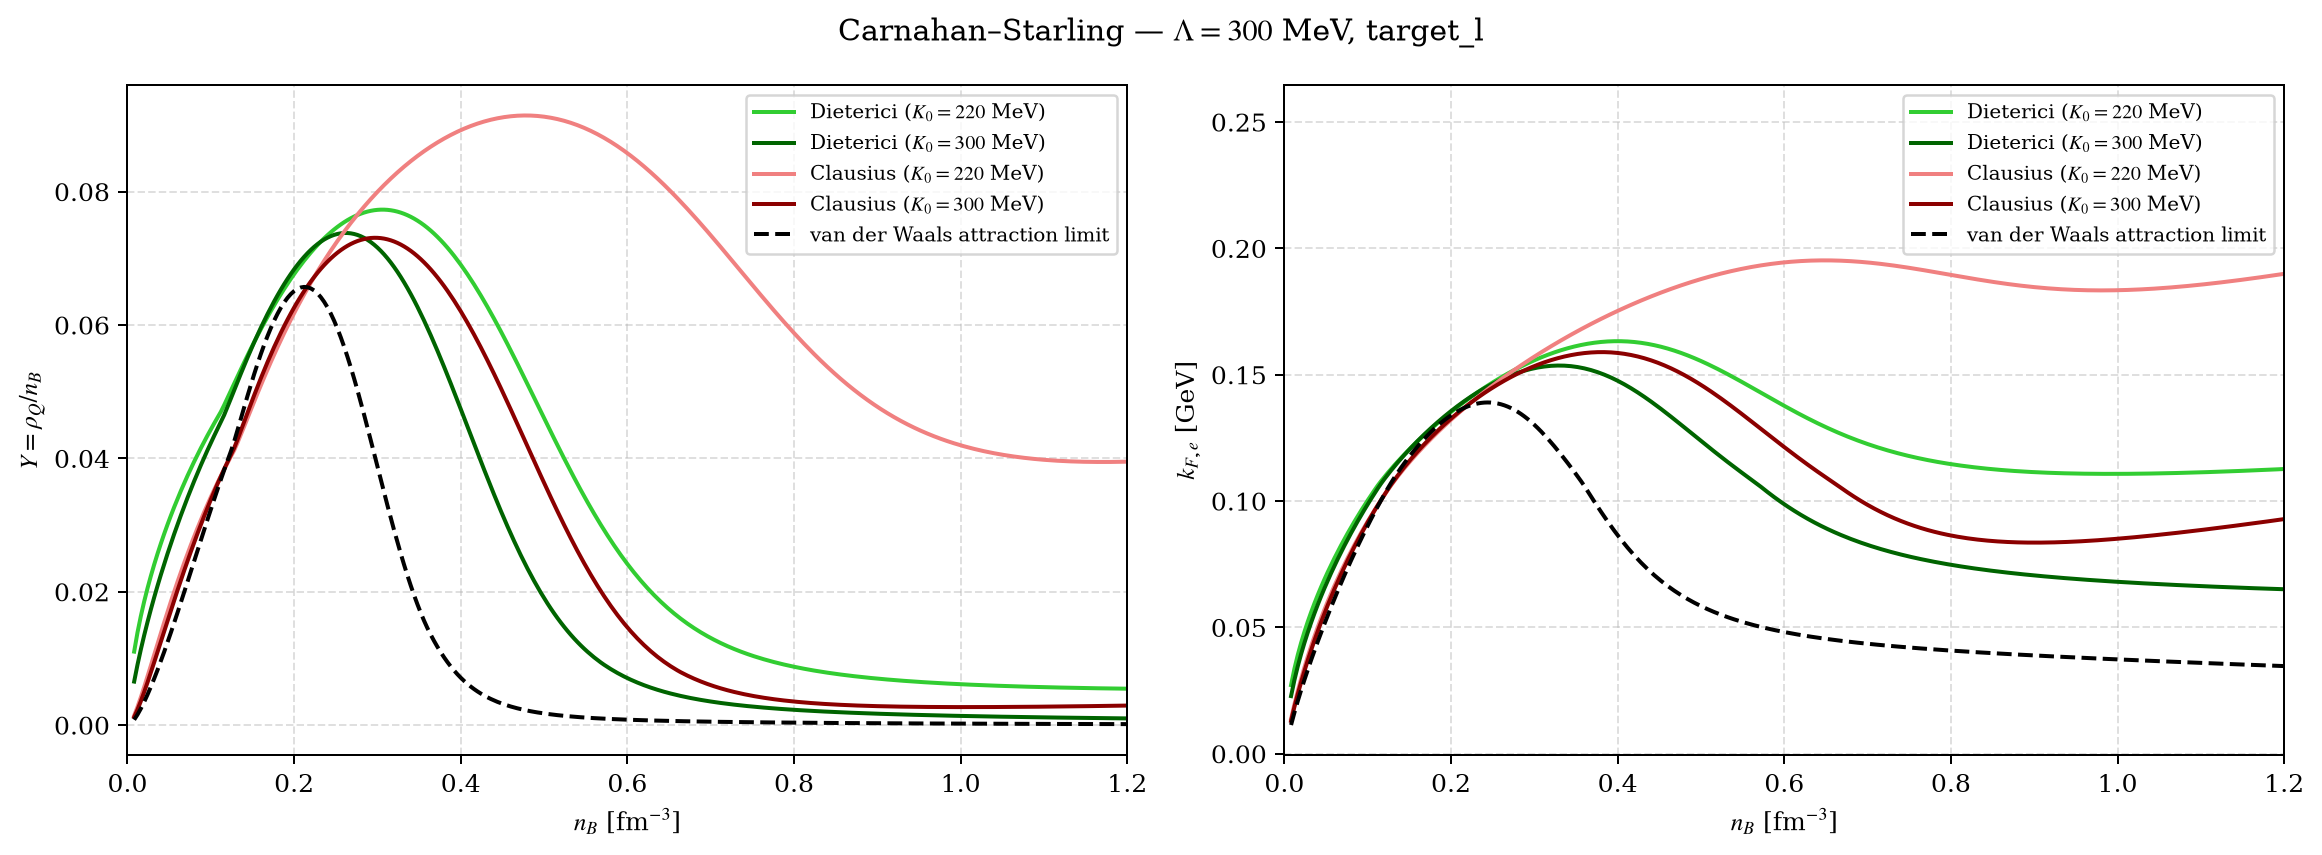

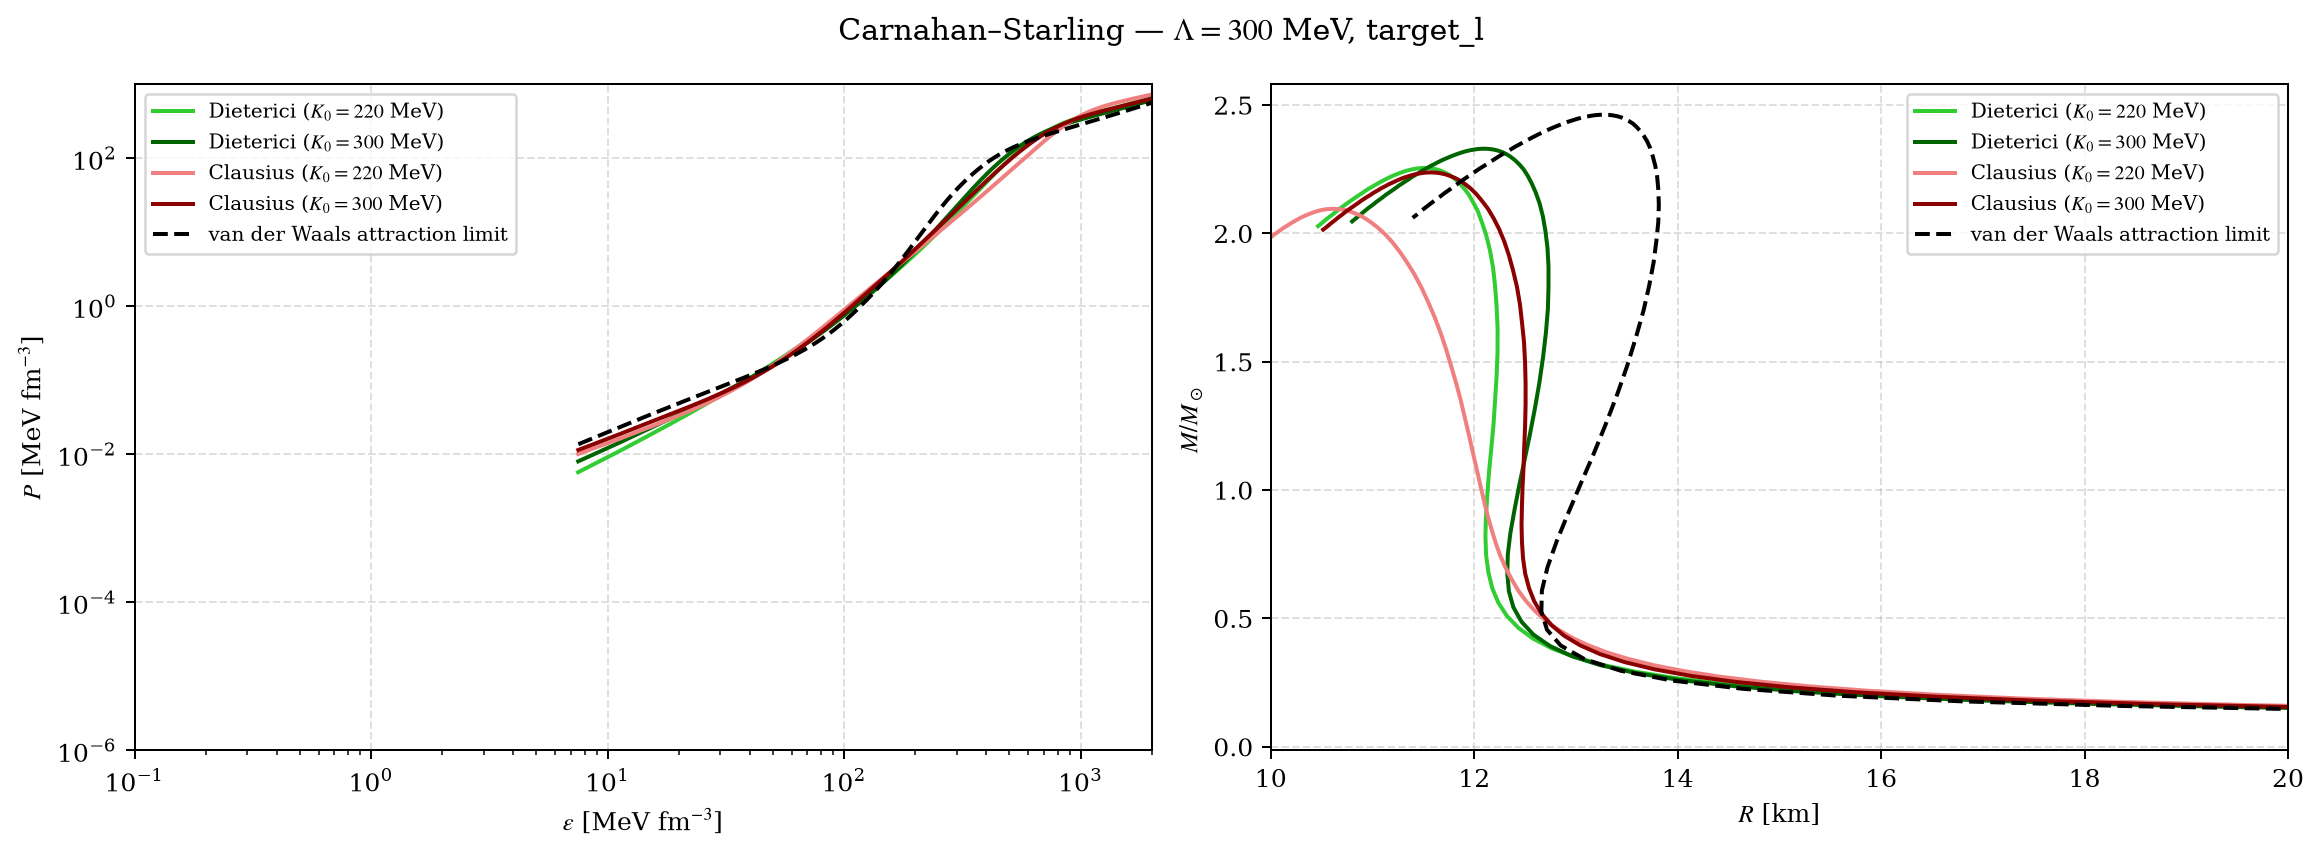

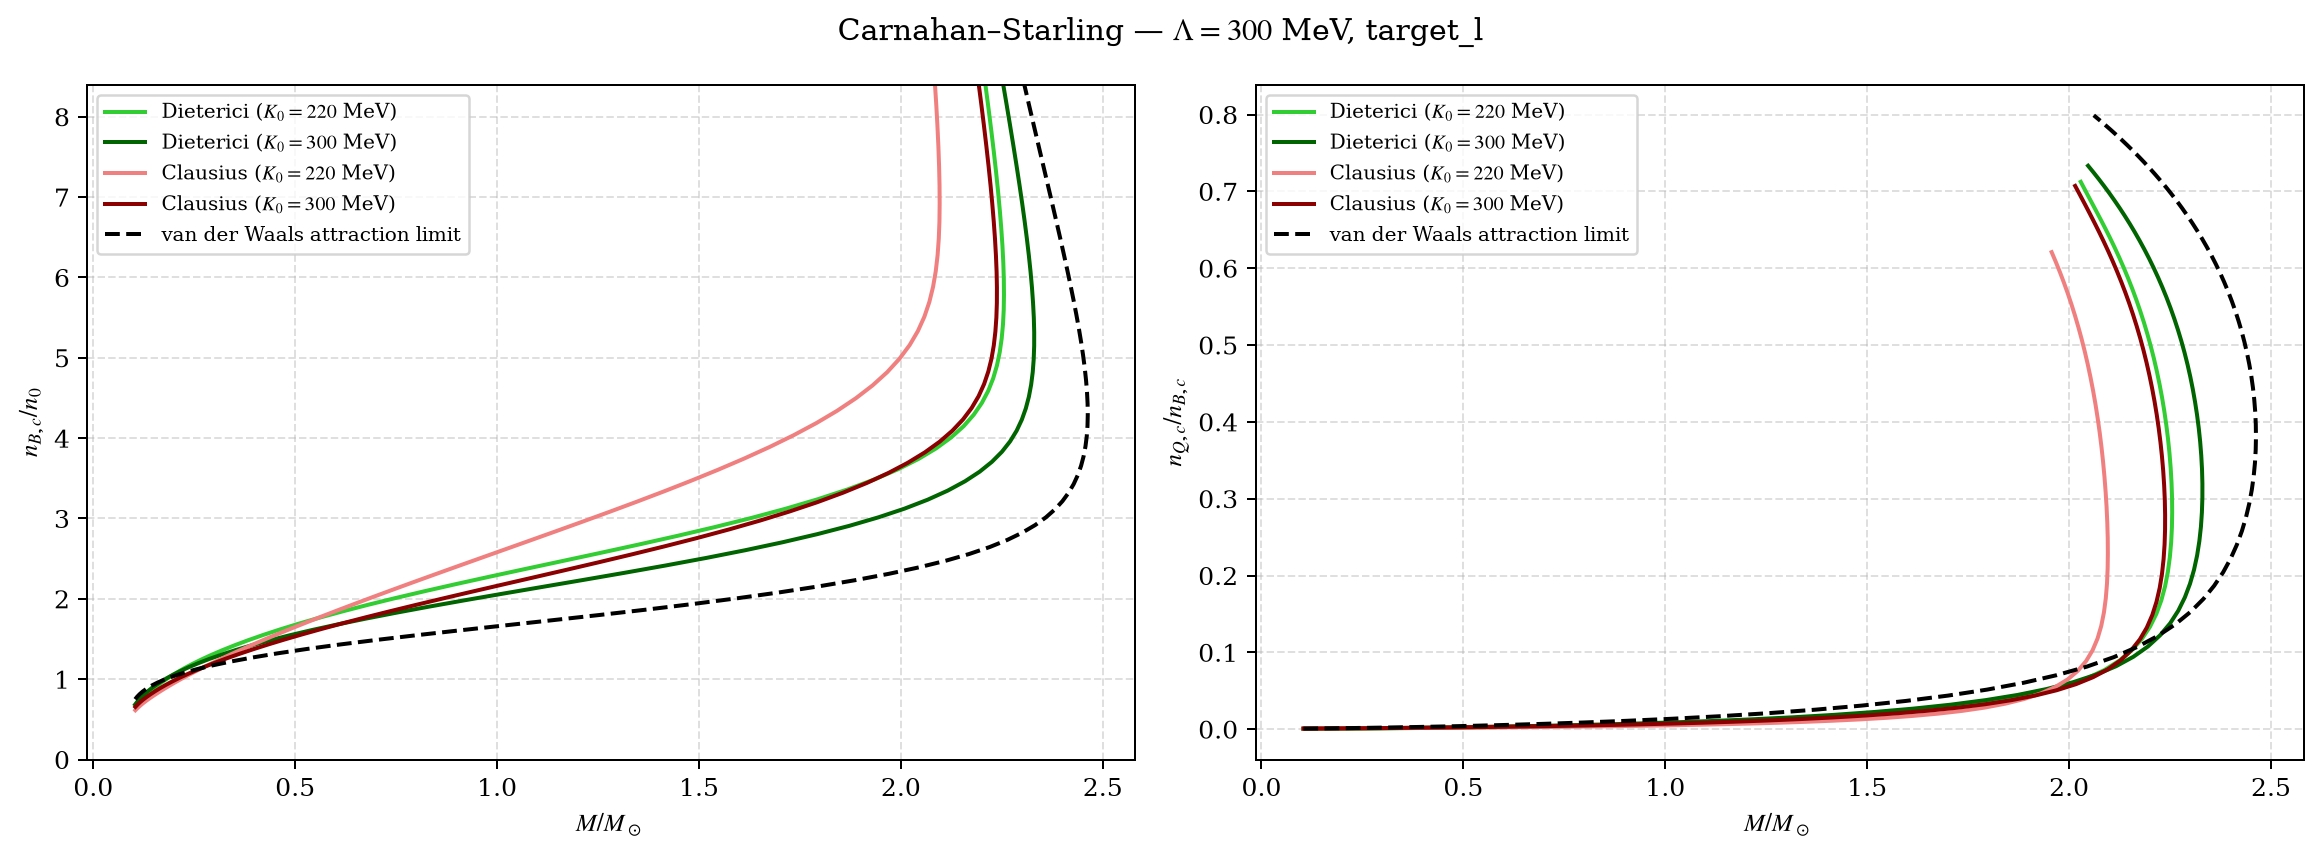

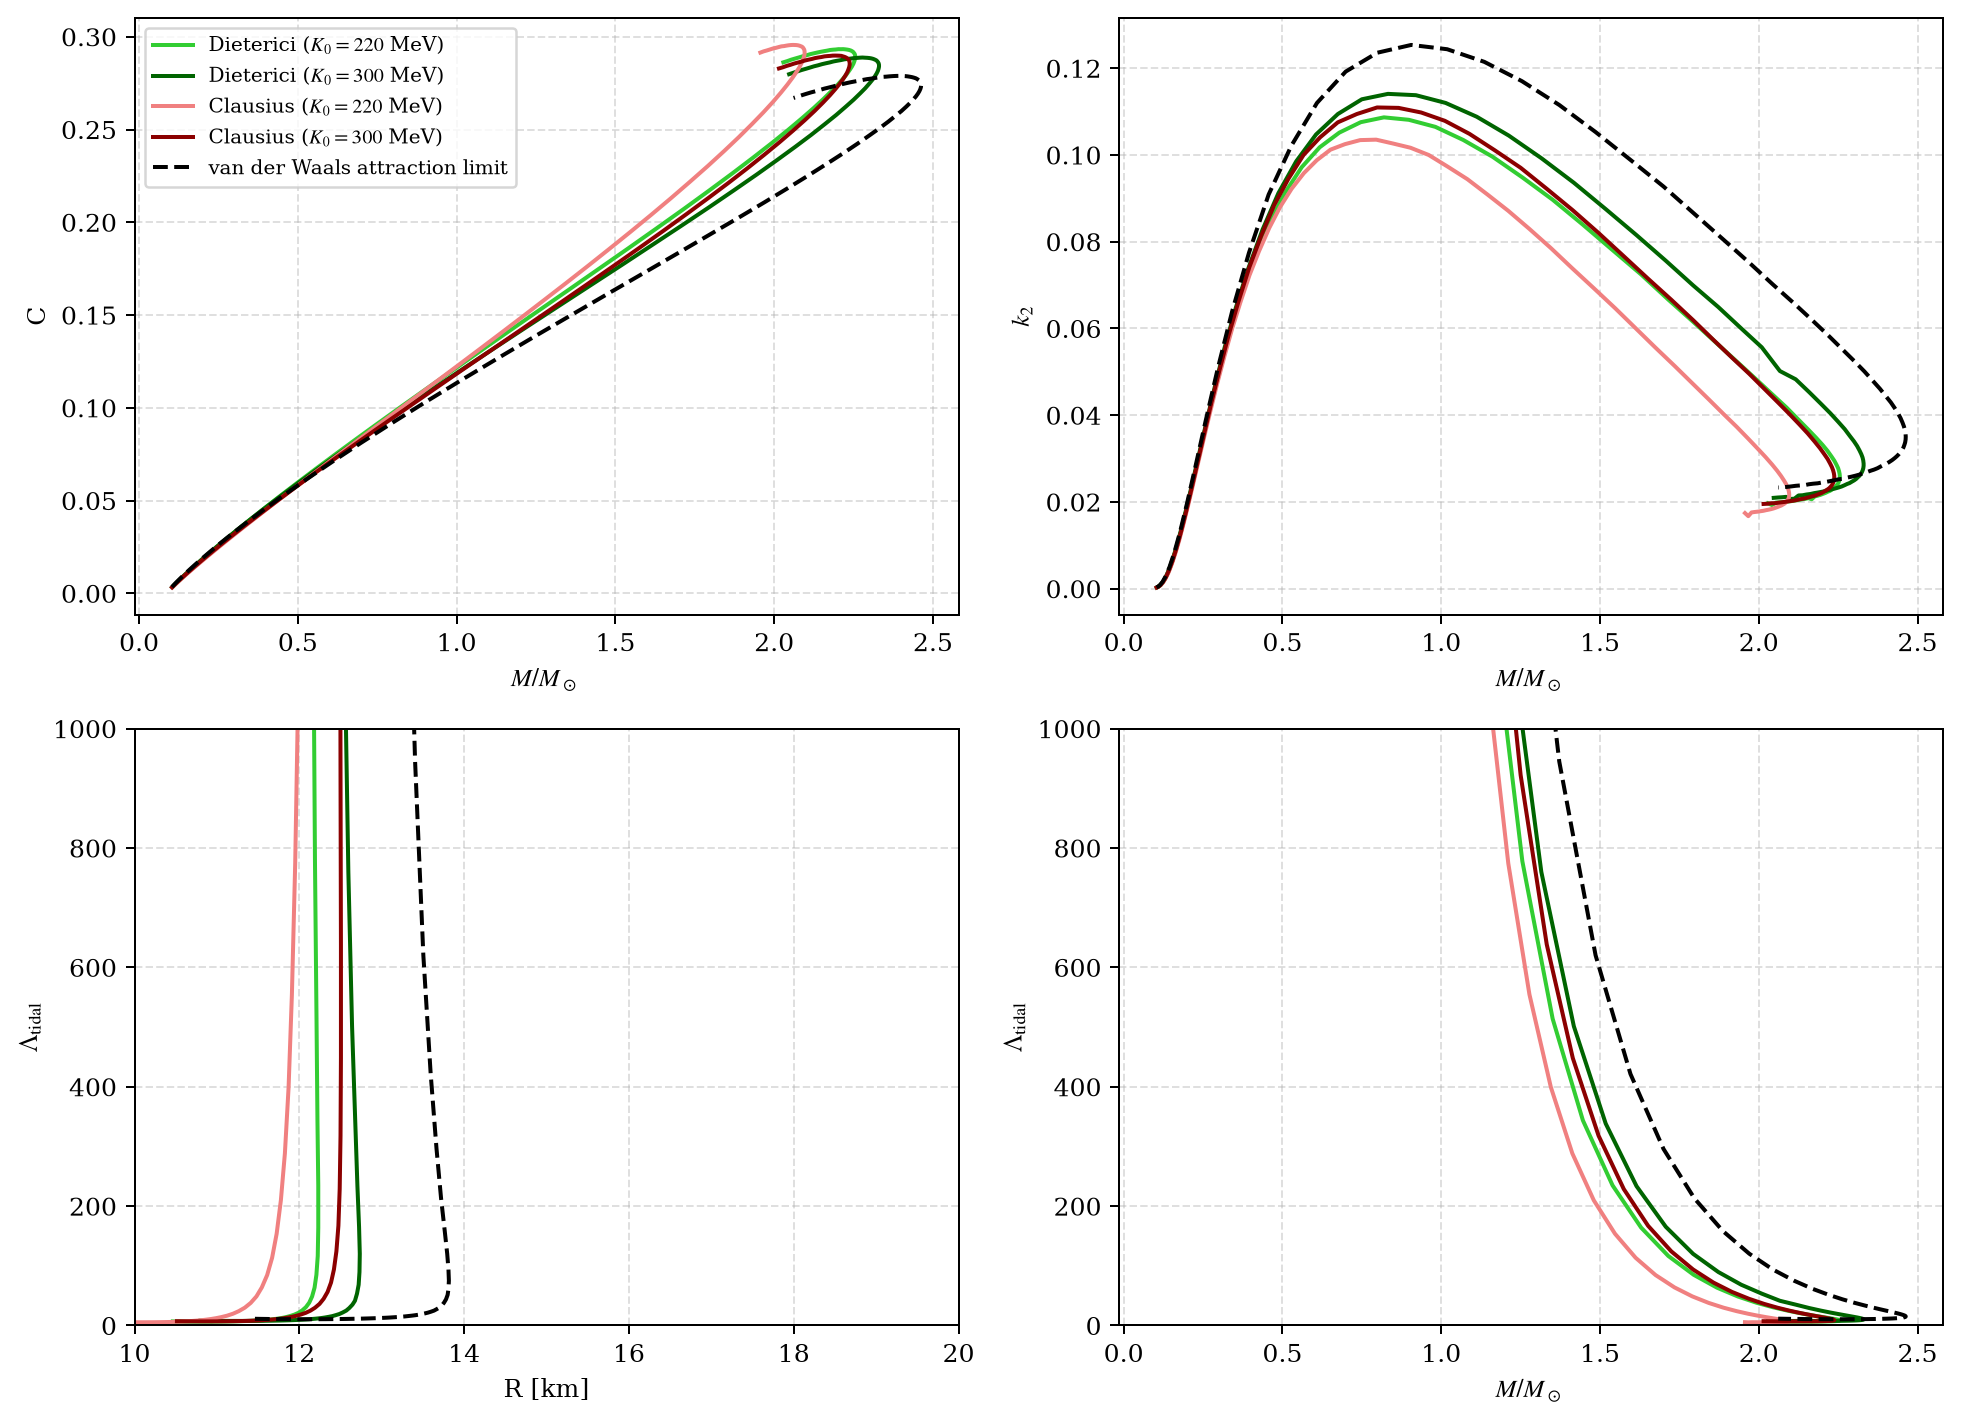

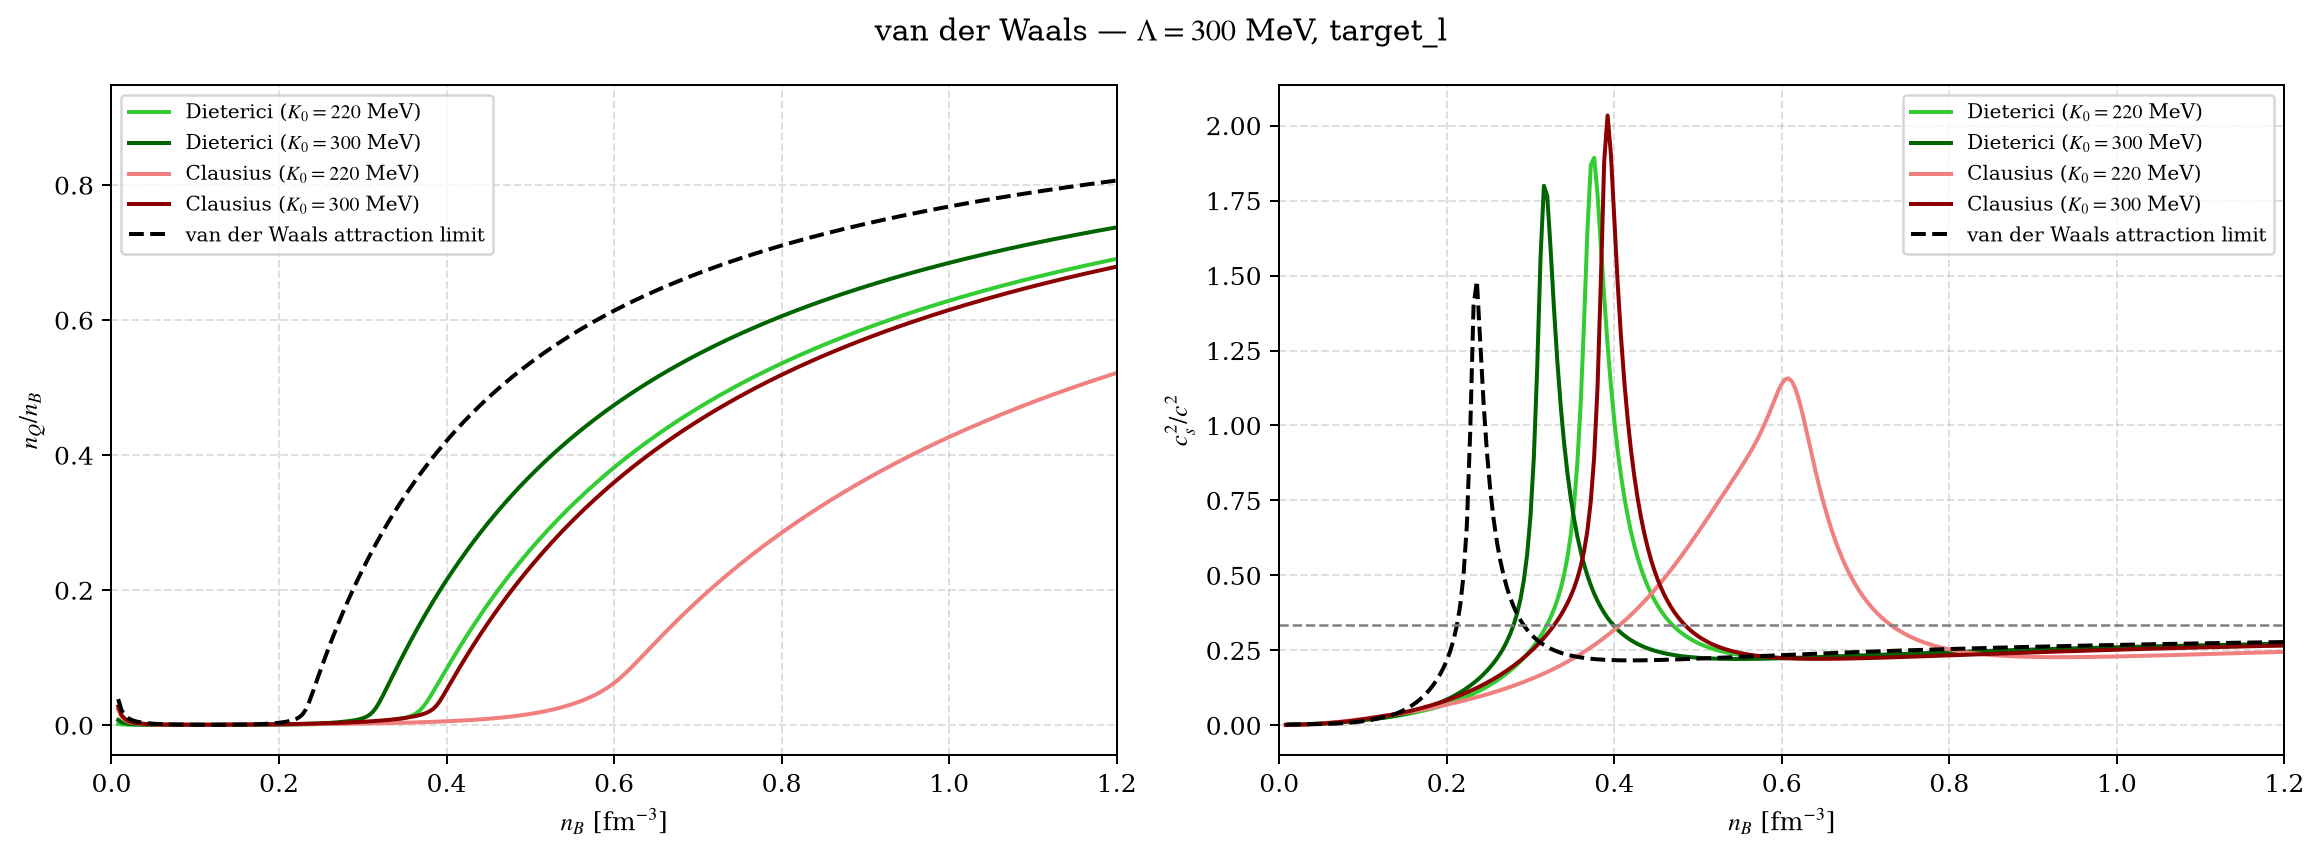

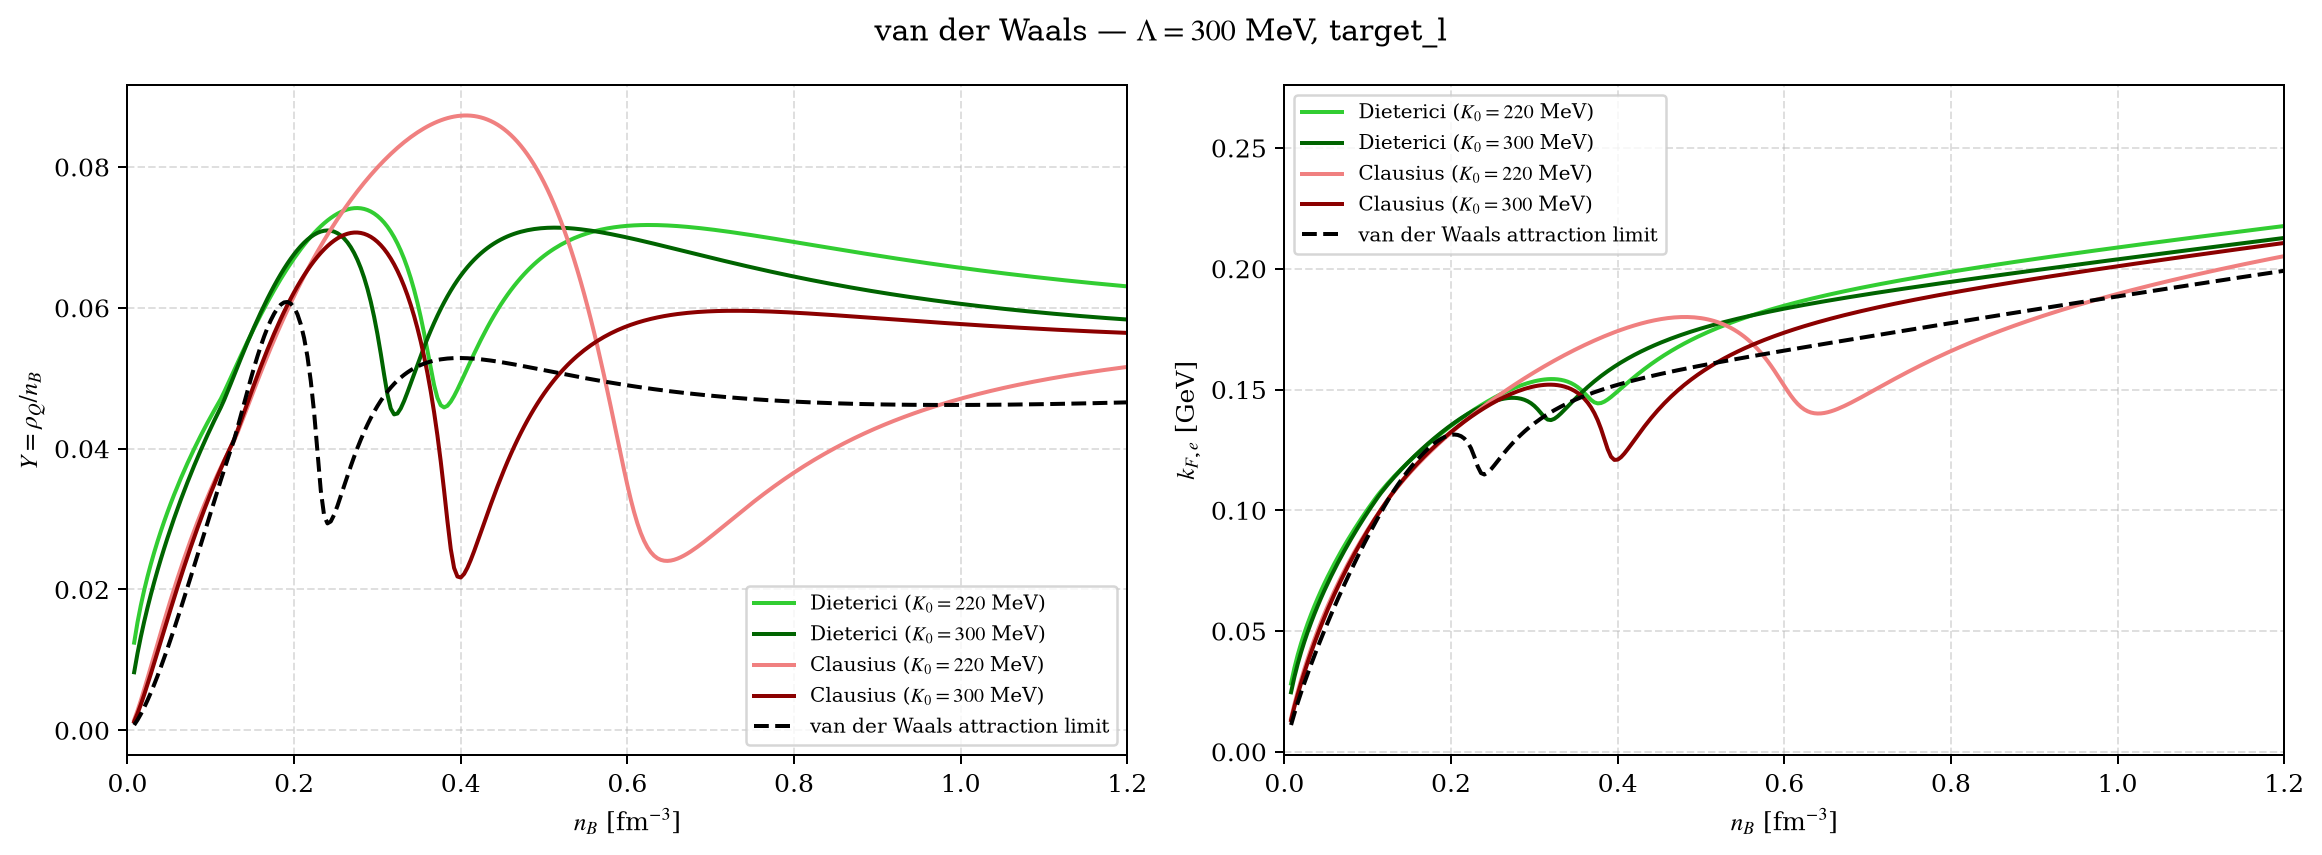

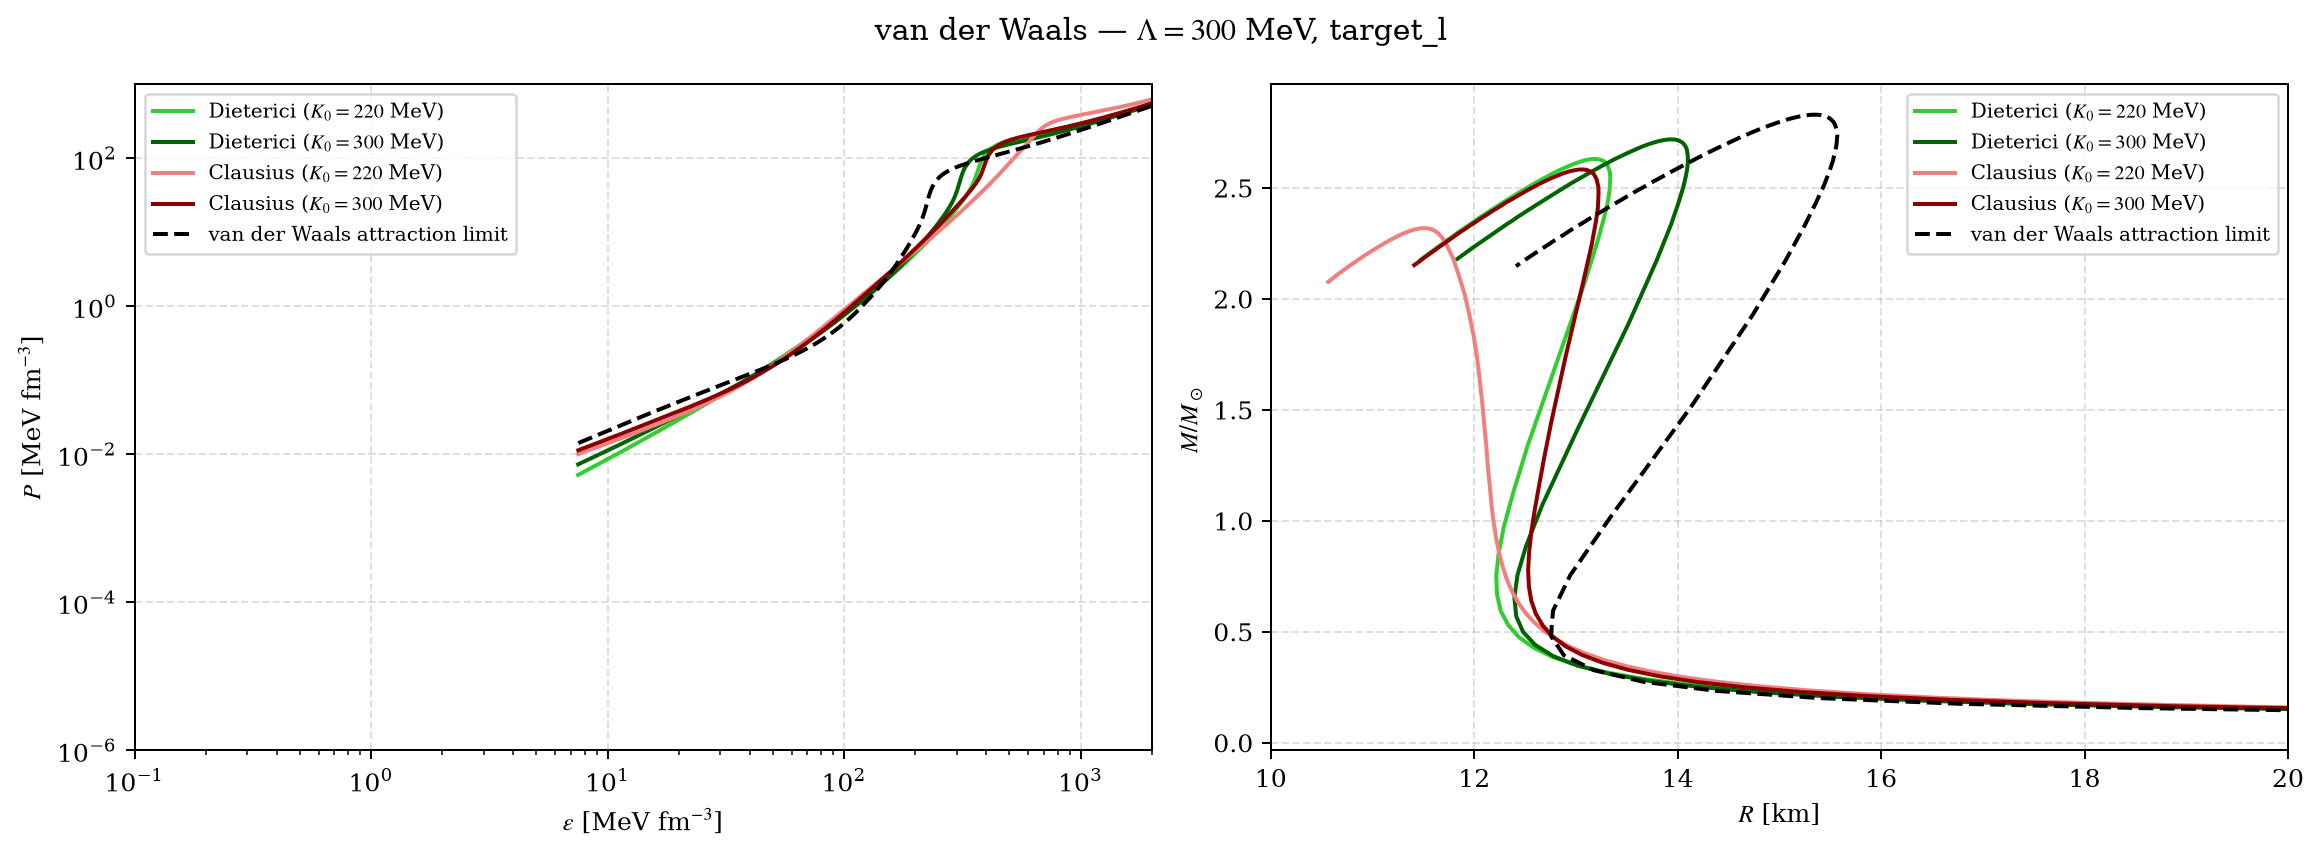

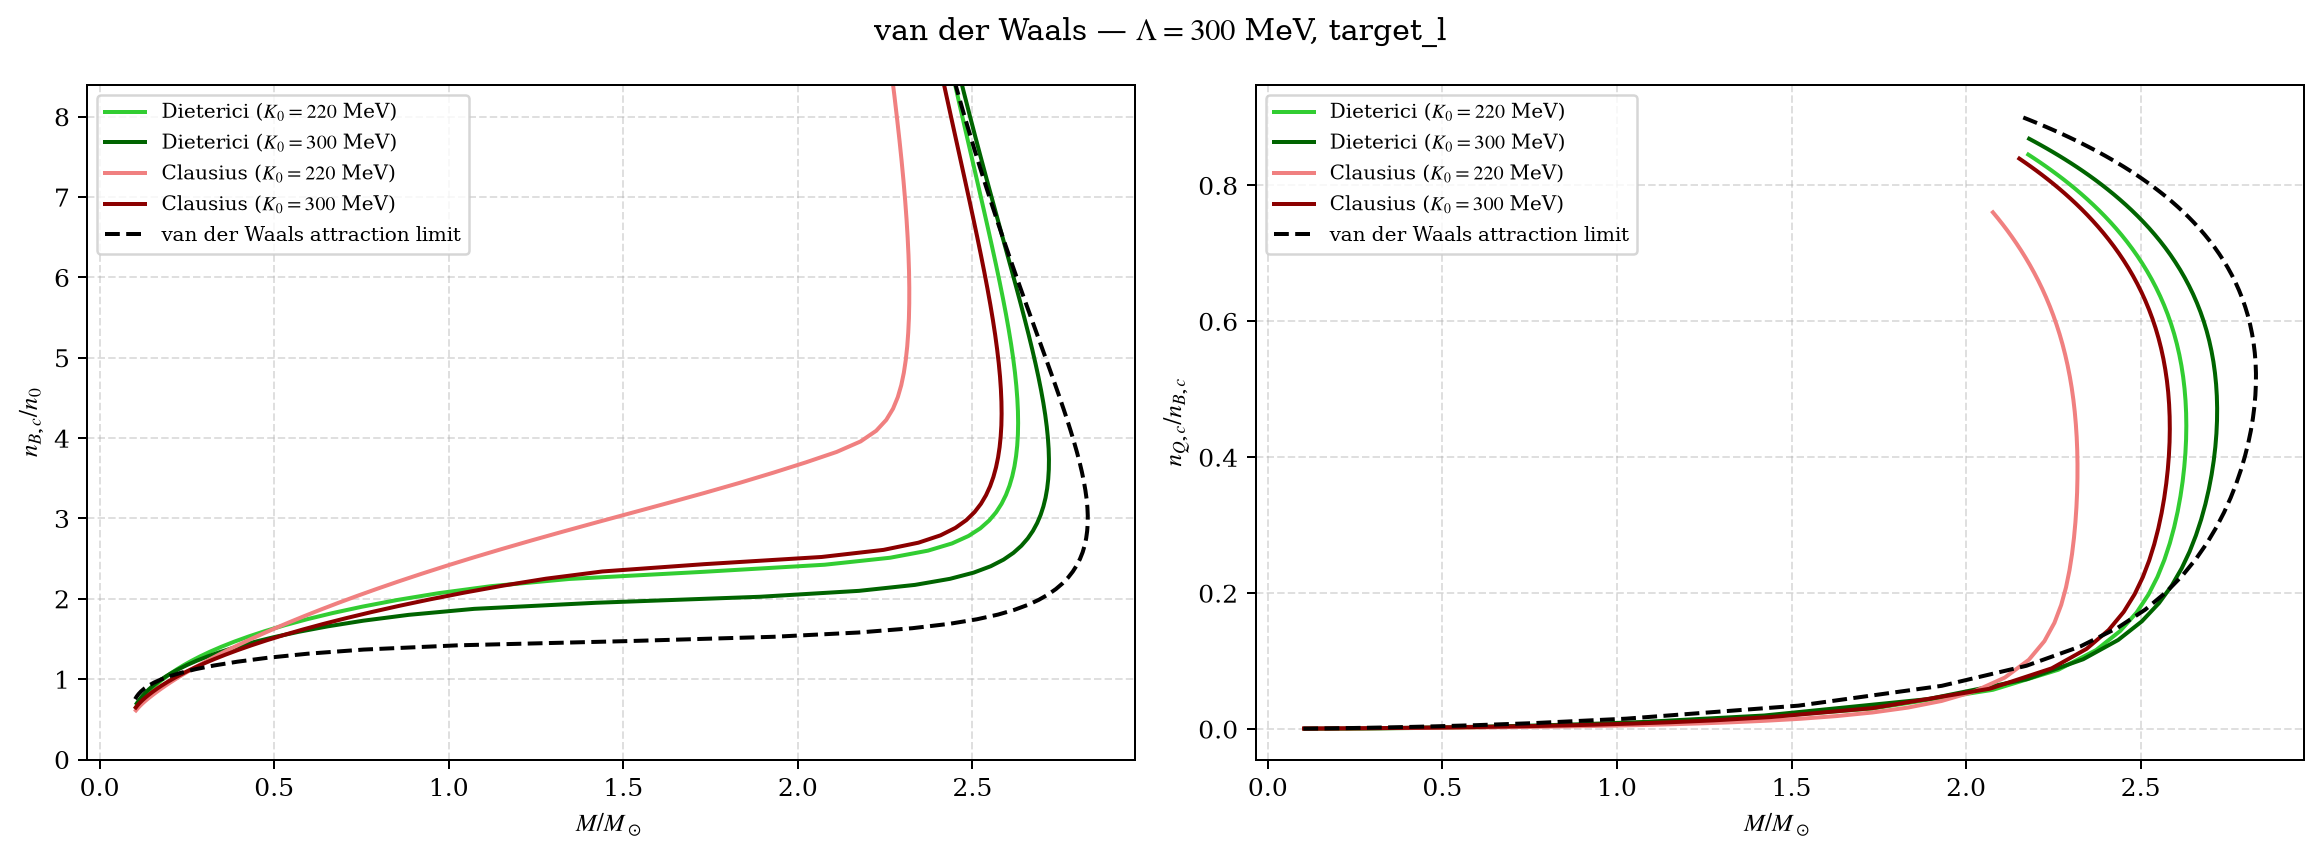

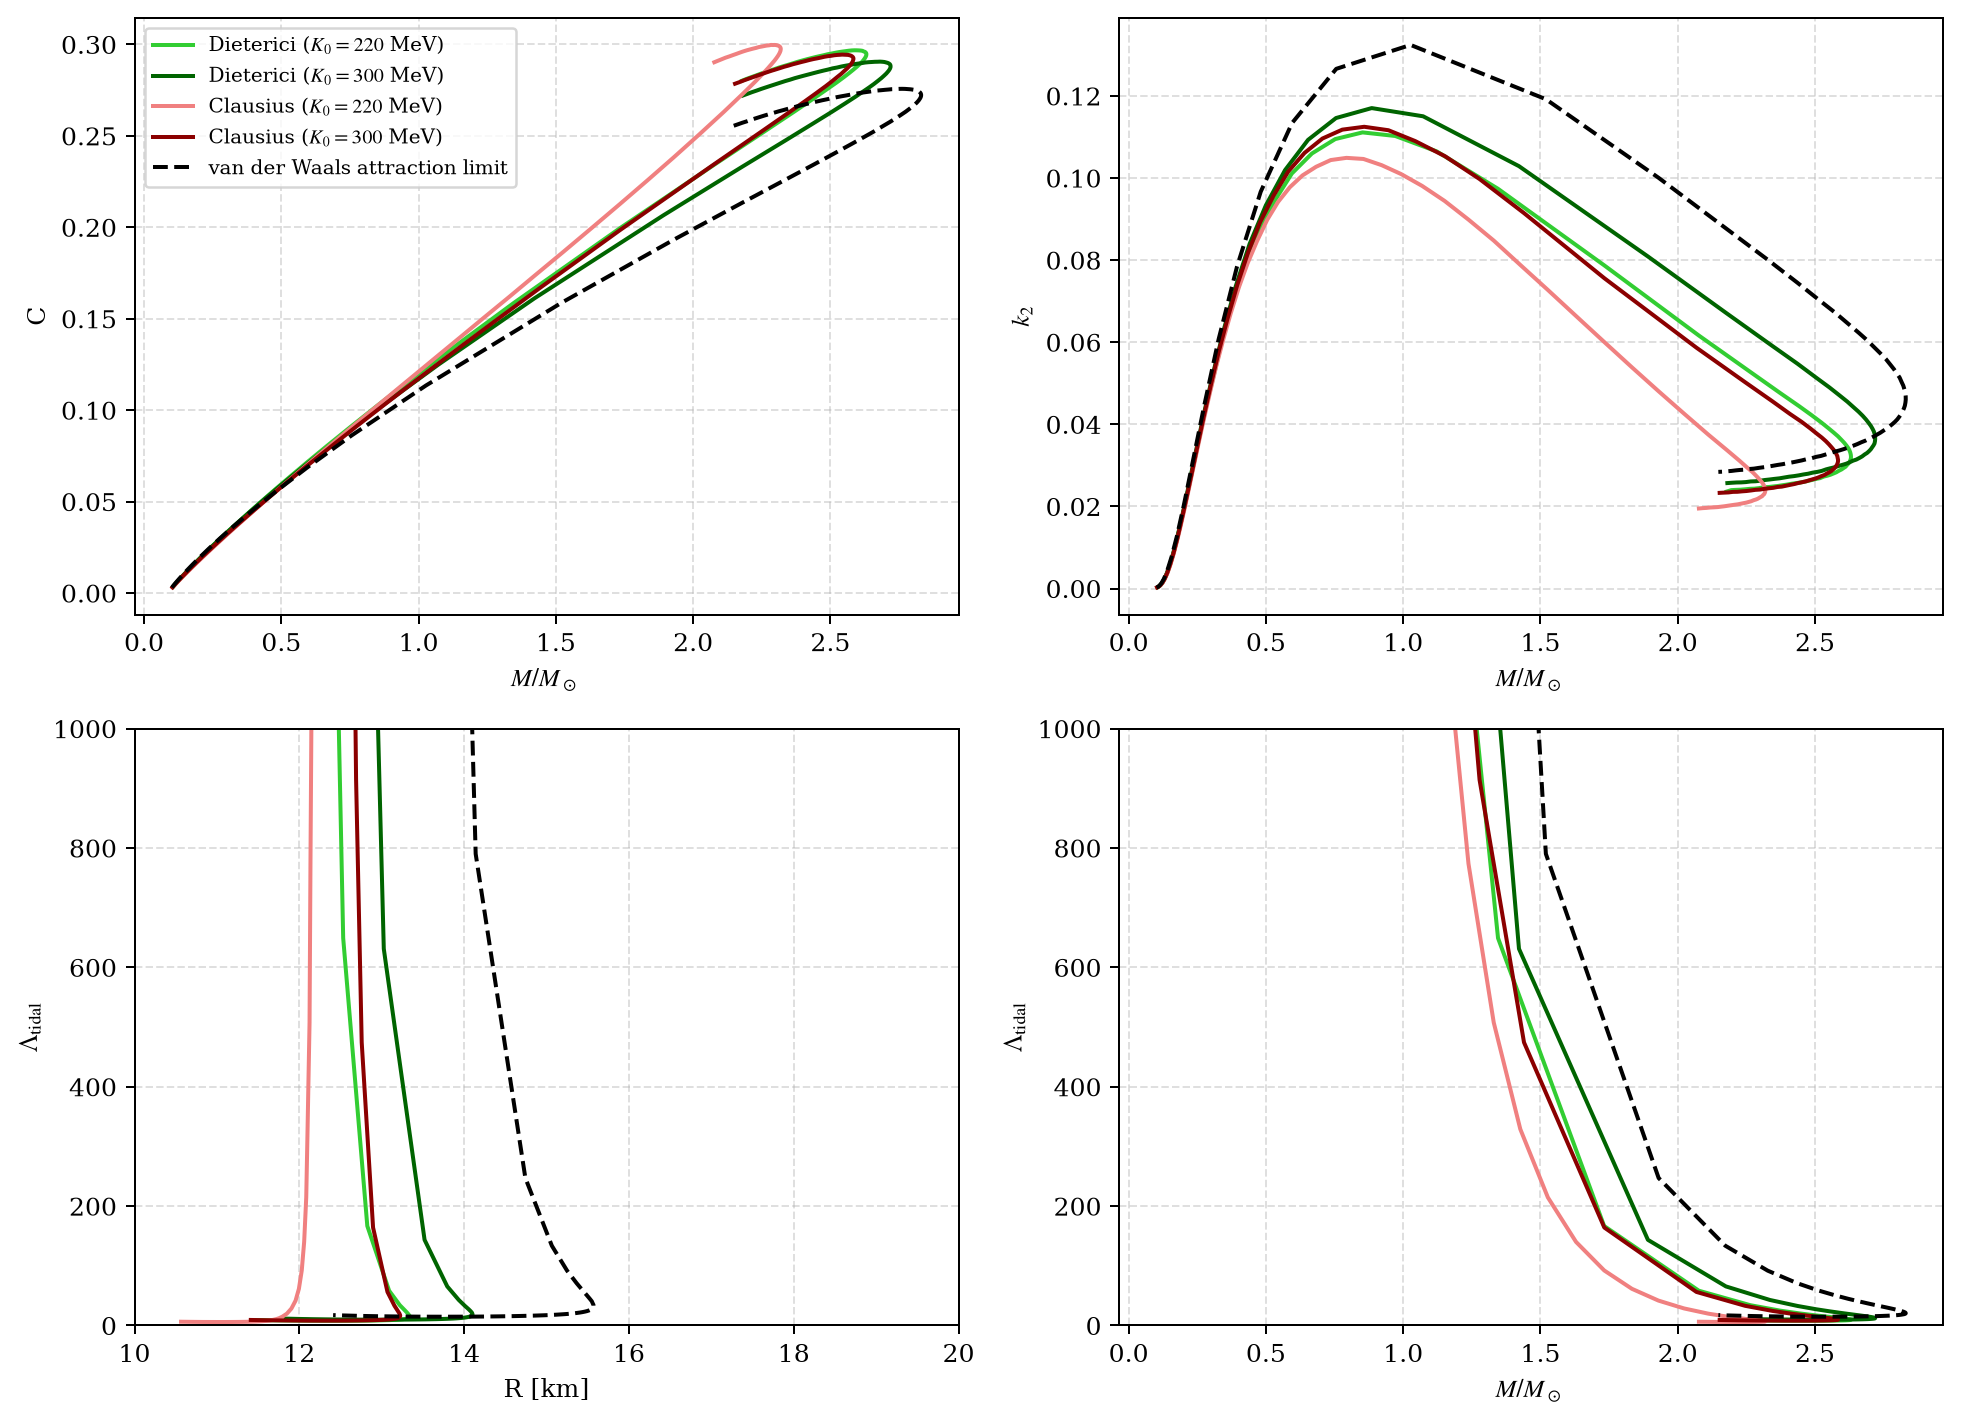

In [6]:
paths=rep.plot_all(jobs,OUT)
print('Saved',len(paths),'files in',OUT)
for ev in rep.EVS:
    for stem in ('fract_speed','charge_fermi','MR','central_fract','tidal'):
        path=OUT/f'{ev}_{stem}.png'
        if path.exists(): display(Image(filename=str(path)))


**Original: Speed_comparison.png**

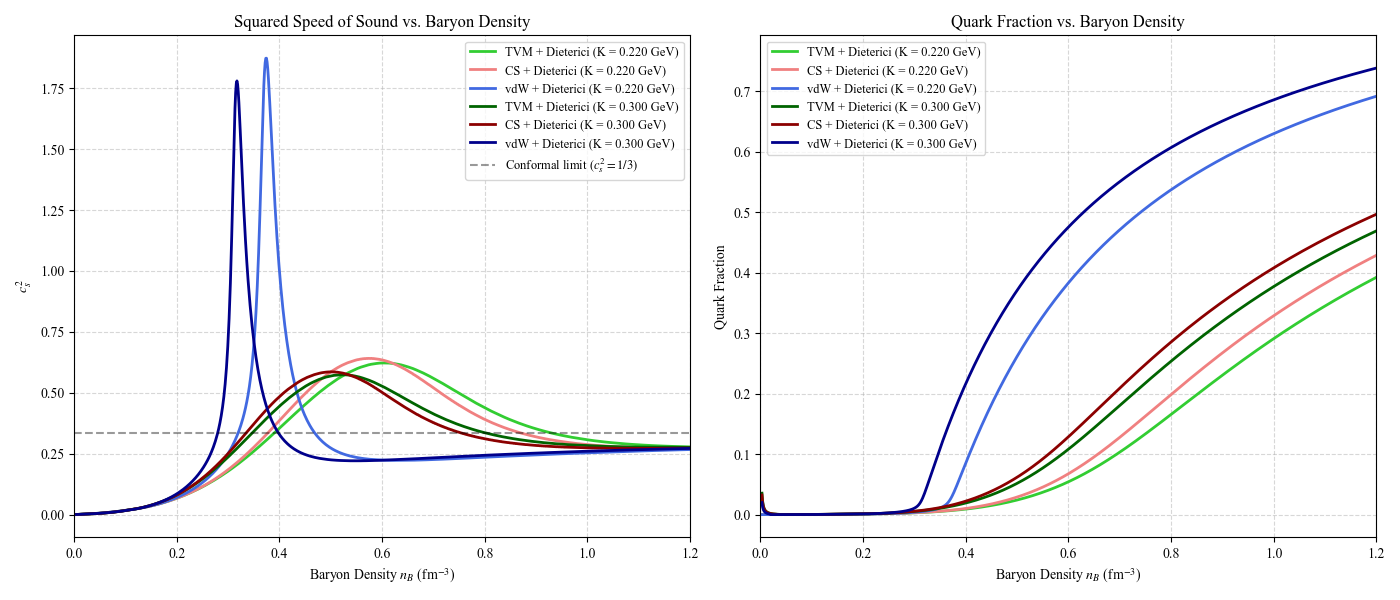

**Original: TVM_fract_speed.png**

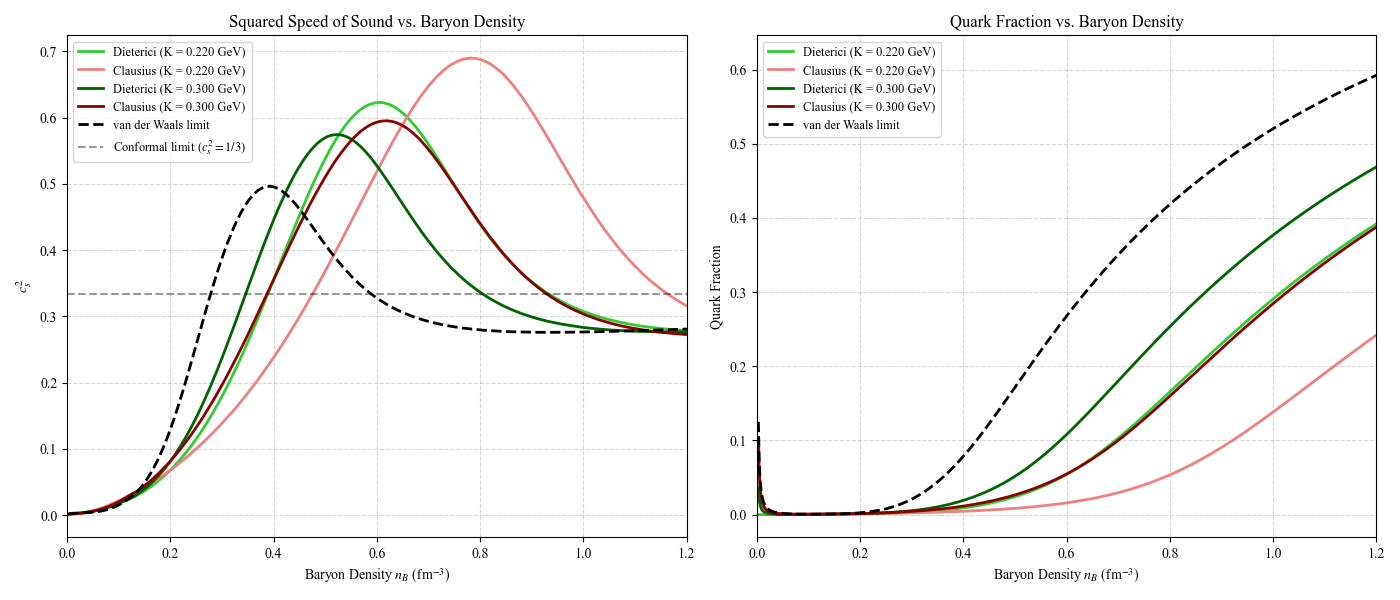

**Original: TVM_qfract_fermi.png**

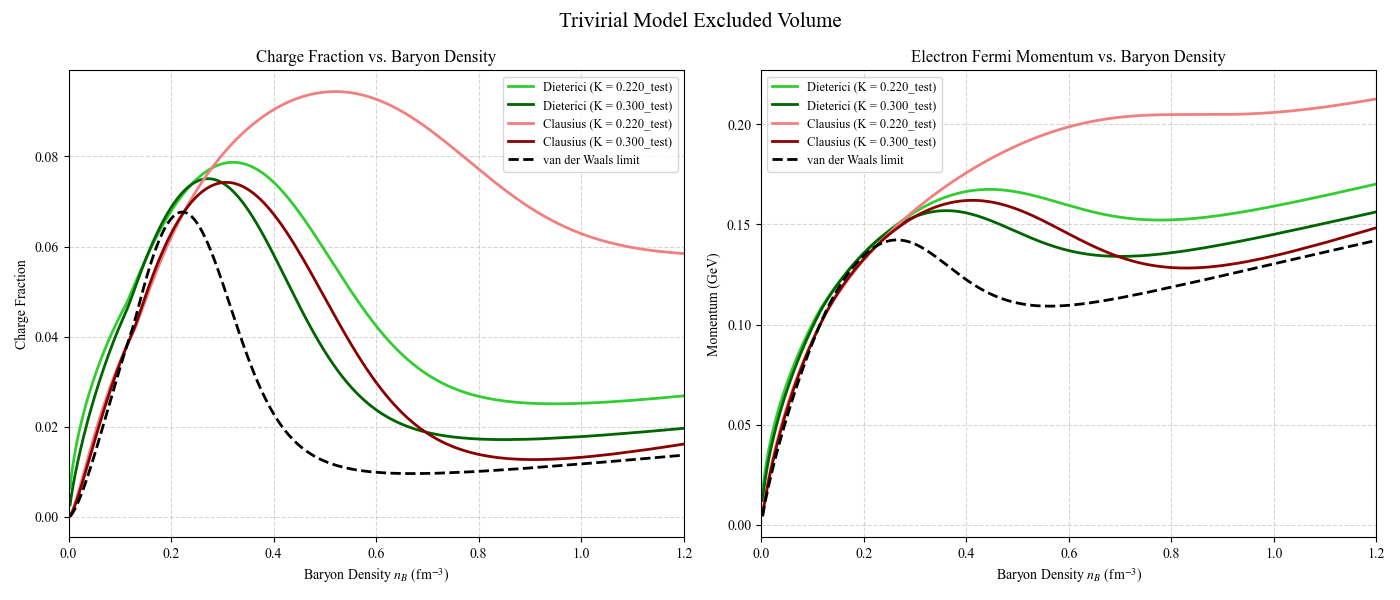

**Original: CS_fract_speed.png**

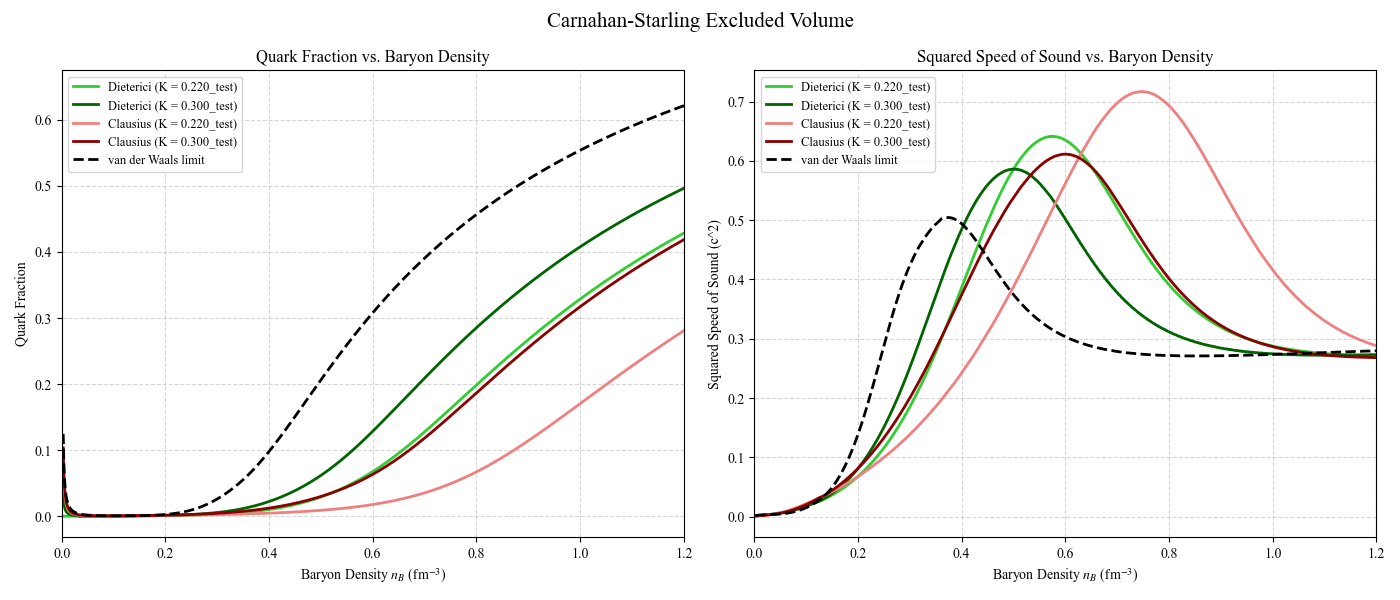

**Original: CS_qfract_fermi.png**

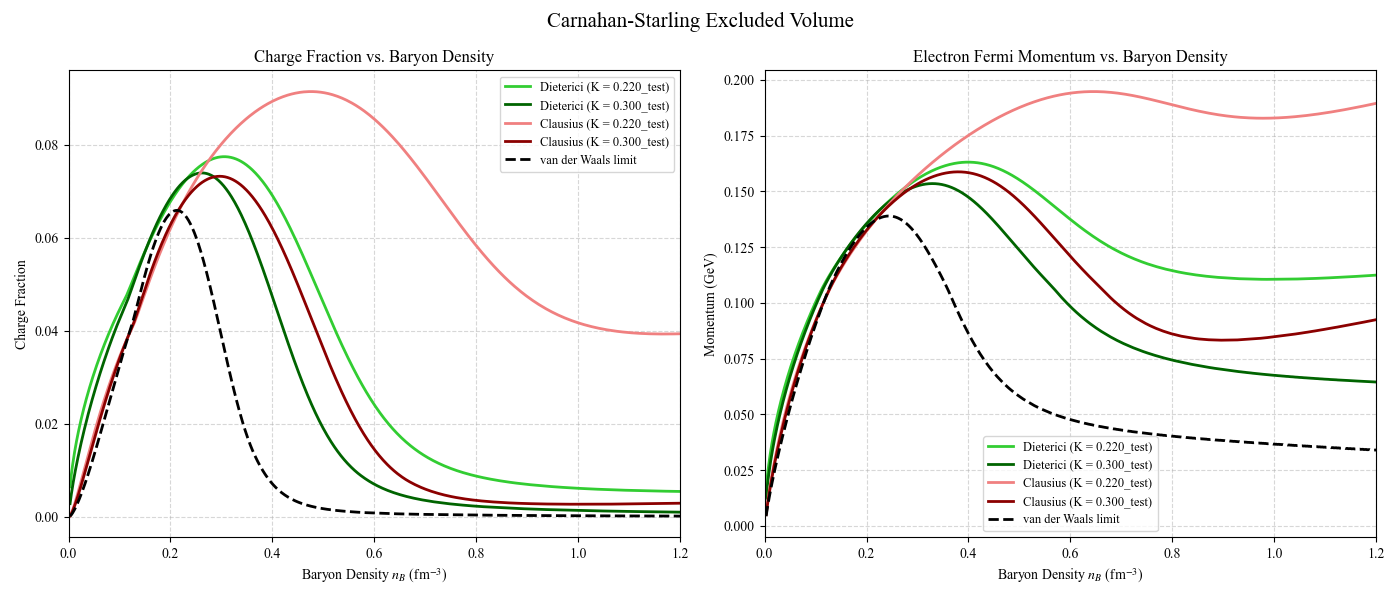

**Original: vdW_fract_sound.png**

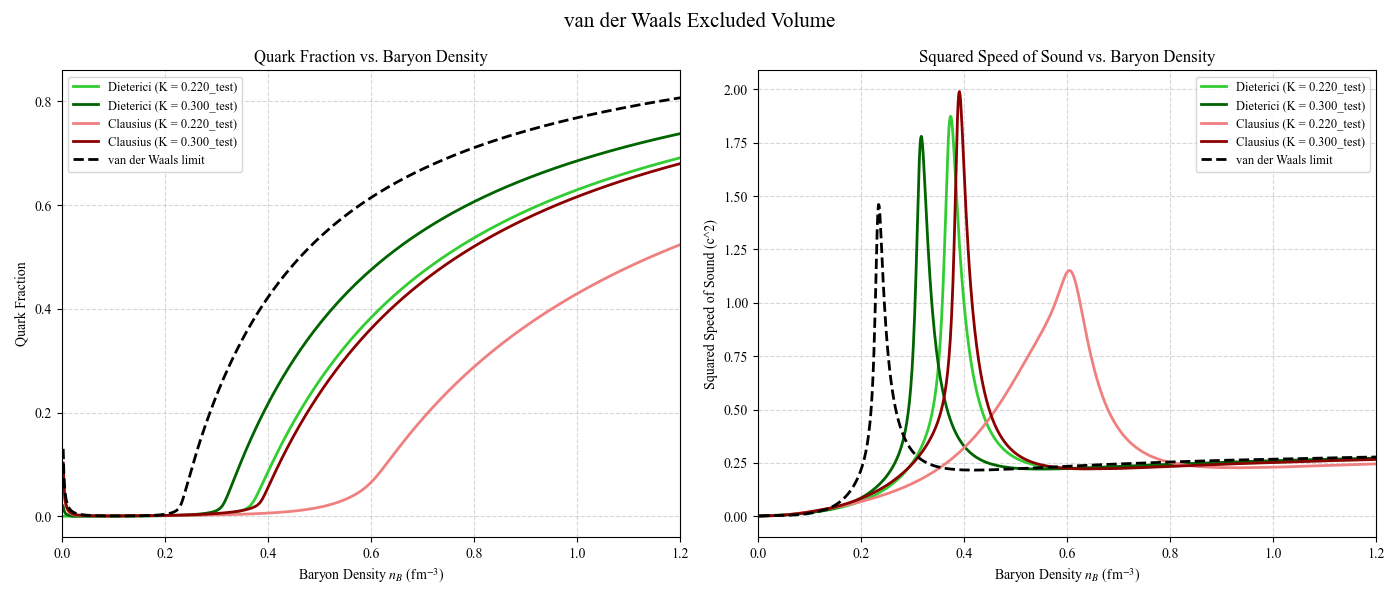

**Original: vdW_qfract_fermi.png**

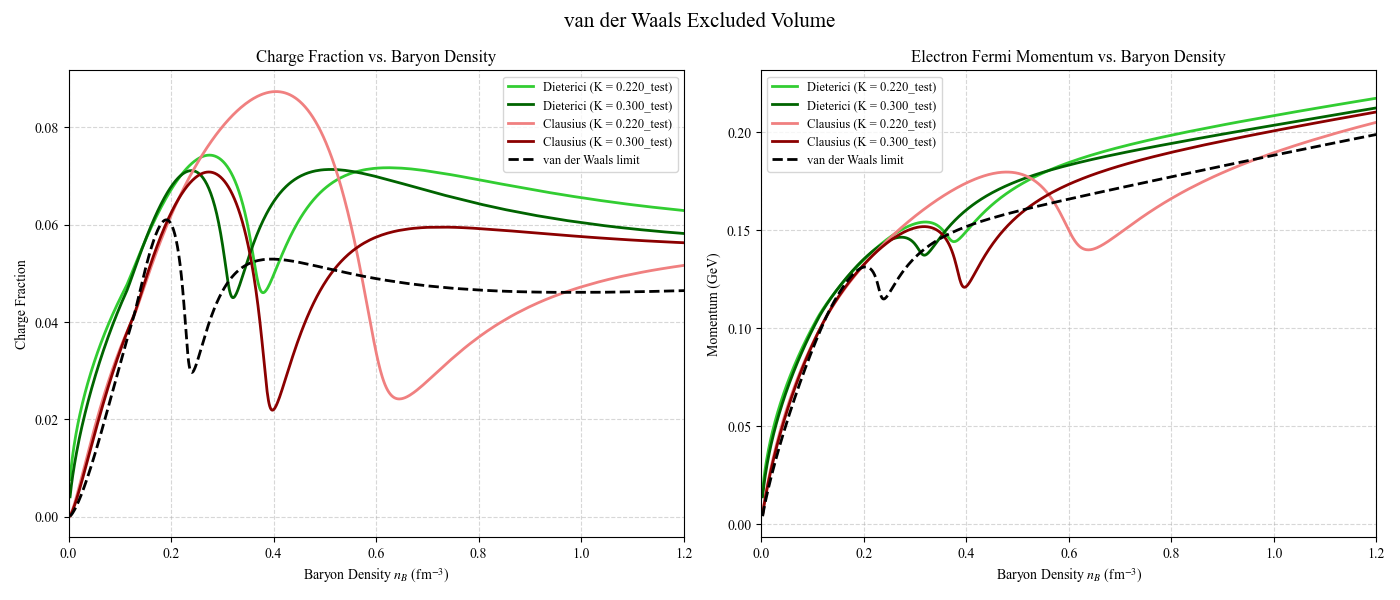

**Original: TVM_MR.png**

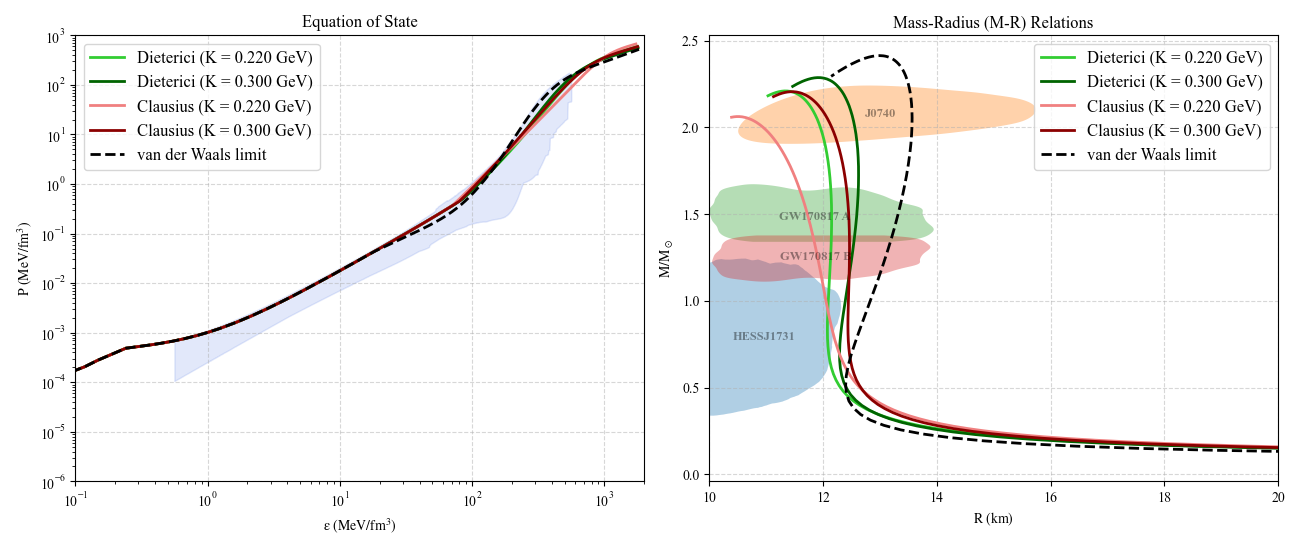

**Original: TVM_tidal.png**

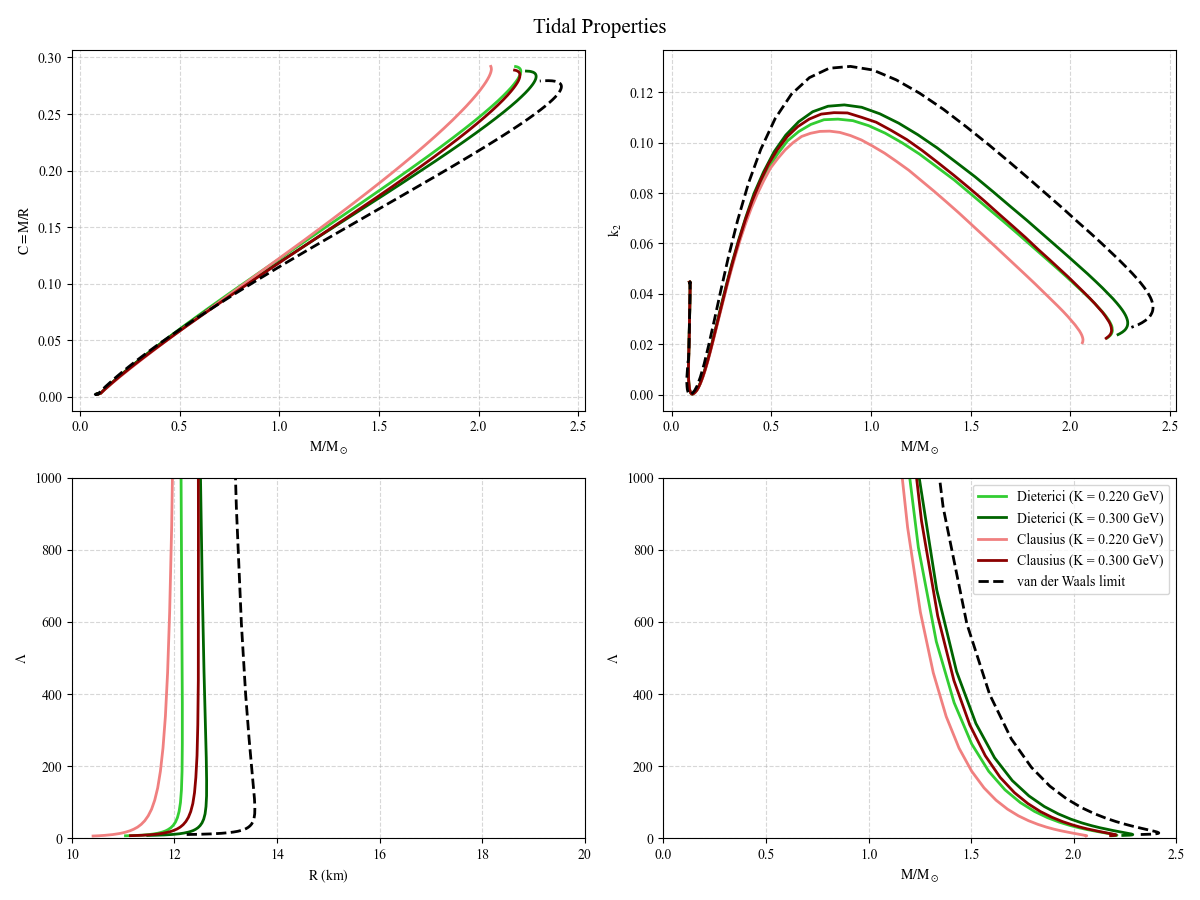

In [7]:
reference_names=['Speed_comparison.png','TVM_fract_speed.png','TVM_qfract_fermi.png','CS_fract_speed.png','CS_qfract_fermi.png','vdW_fract_sound.png','vdW_qfract_fermi.png','TVM_MR.png','TVM_tidal.png']
for name in reference_names:
    path=PAPER/name
    if path.exists():
        display(Markdown('**Original: '+name+'**'))
        display(Image(filename=str(path)))


## Pixel-level reference comparison and audit

If the checked-in comparison script and audit files exist, display the measured figure differences. Pixel digitization is approximate and excludes legends/occluded segments. Original numerical data would be needed for a numerical identity claim.

legacy_comparison.csv
validation_summary.csv


,model,K0_MeV,observable,points,RMSE,max_abs_error,vertical_pixel_units,source
0,dieterici_tvm,220.0,vs2,390,0.002202,0.006265,0.001509,TVM_fract_speed.png
1,dieterici_tvm,220.0,quark_fraction,347,0.002601,0.004303,0.001350,TVM_fract_speed.png
2,dieterici_tvm,220.0,y,523,0.000249,0.001230,0.000222,TVM_qfract_fermi.png
3,dieterici_tvm,220.0,electron_kf_GeV,431,0.000244,0.001453,0.000499,TVM_qfract_fermi.png
4,dieterici_tvm,300.0,vs2,481,0.002017,0.004136,0.001509,TVM_fract_speed.png
5,dieterici_tvm,300.0,quark_fraction,443,0.002419,0.003246,0.001350,TVM_fract_speed.png
6,dieterici_tvm,300.0,y,539,0.000284,0.000908,0.000222,TVM_qfract_fermi.png
7,dieterici_tvm,300.0,electron_kf_GeV,512,0.000244,0.000833,0.000499,TVM_qfract_fermi.png
8,clausius_tvm,220.0,vs2,519,0.004269,0.008766,0.001509,TVM_fract_speed.png
9,clausius_tvm,220.0,quark_fraction,460,0.002667,0.004355,0.001350,TVM_fract_speed.png


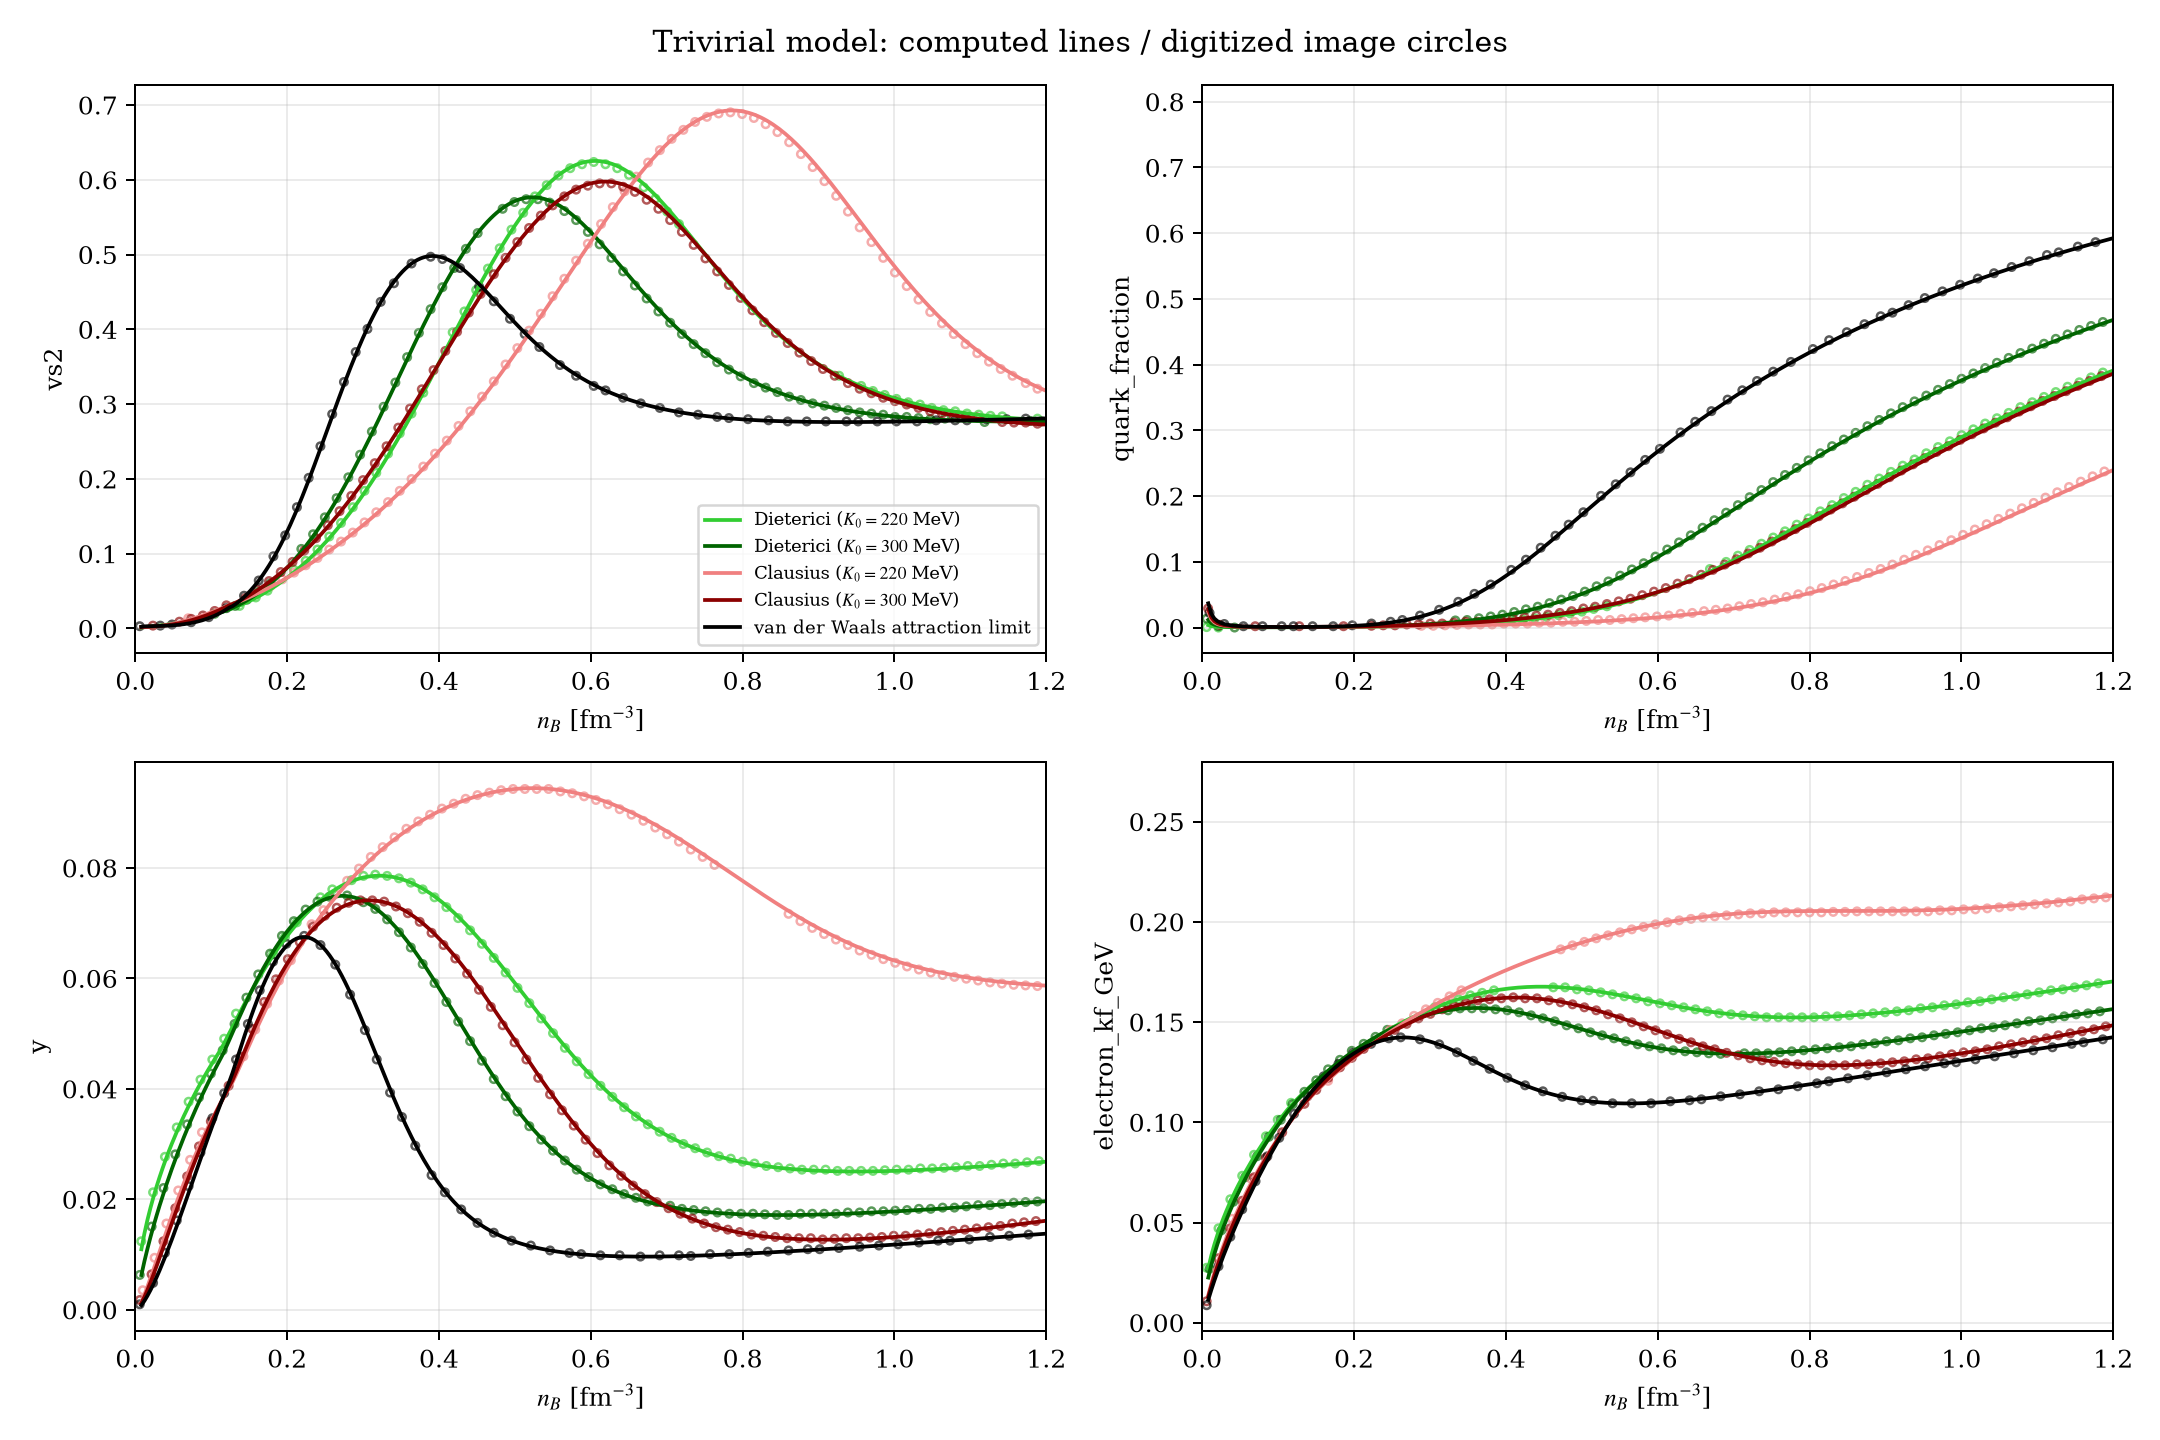

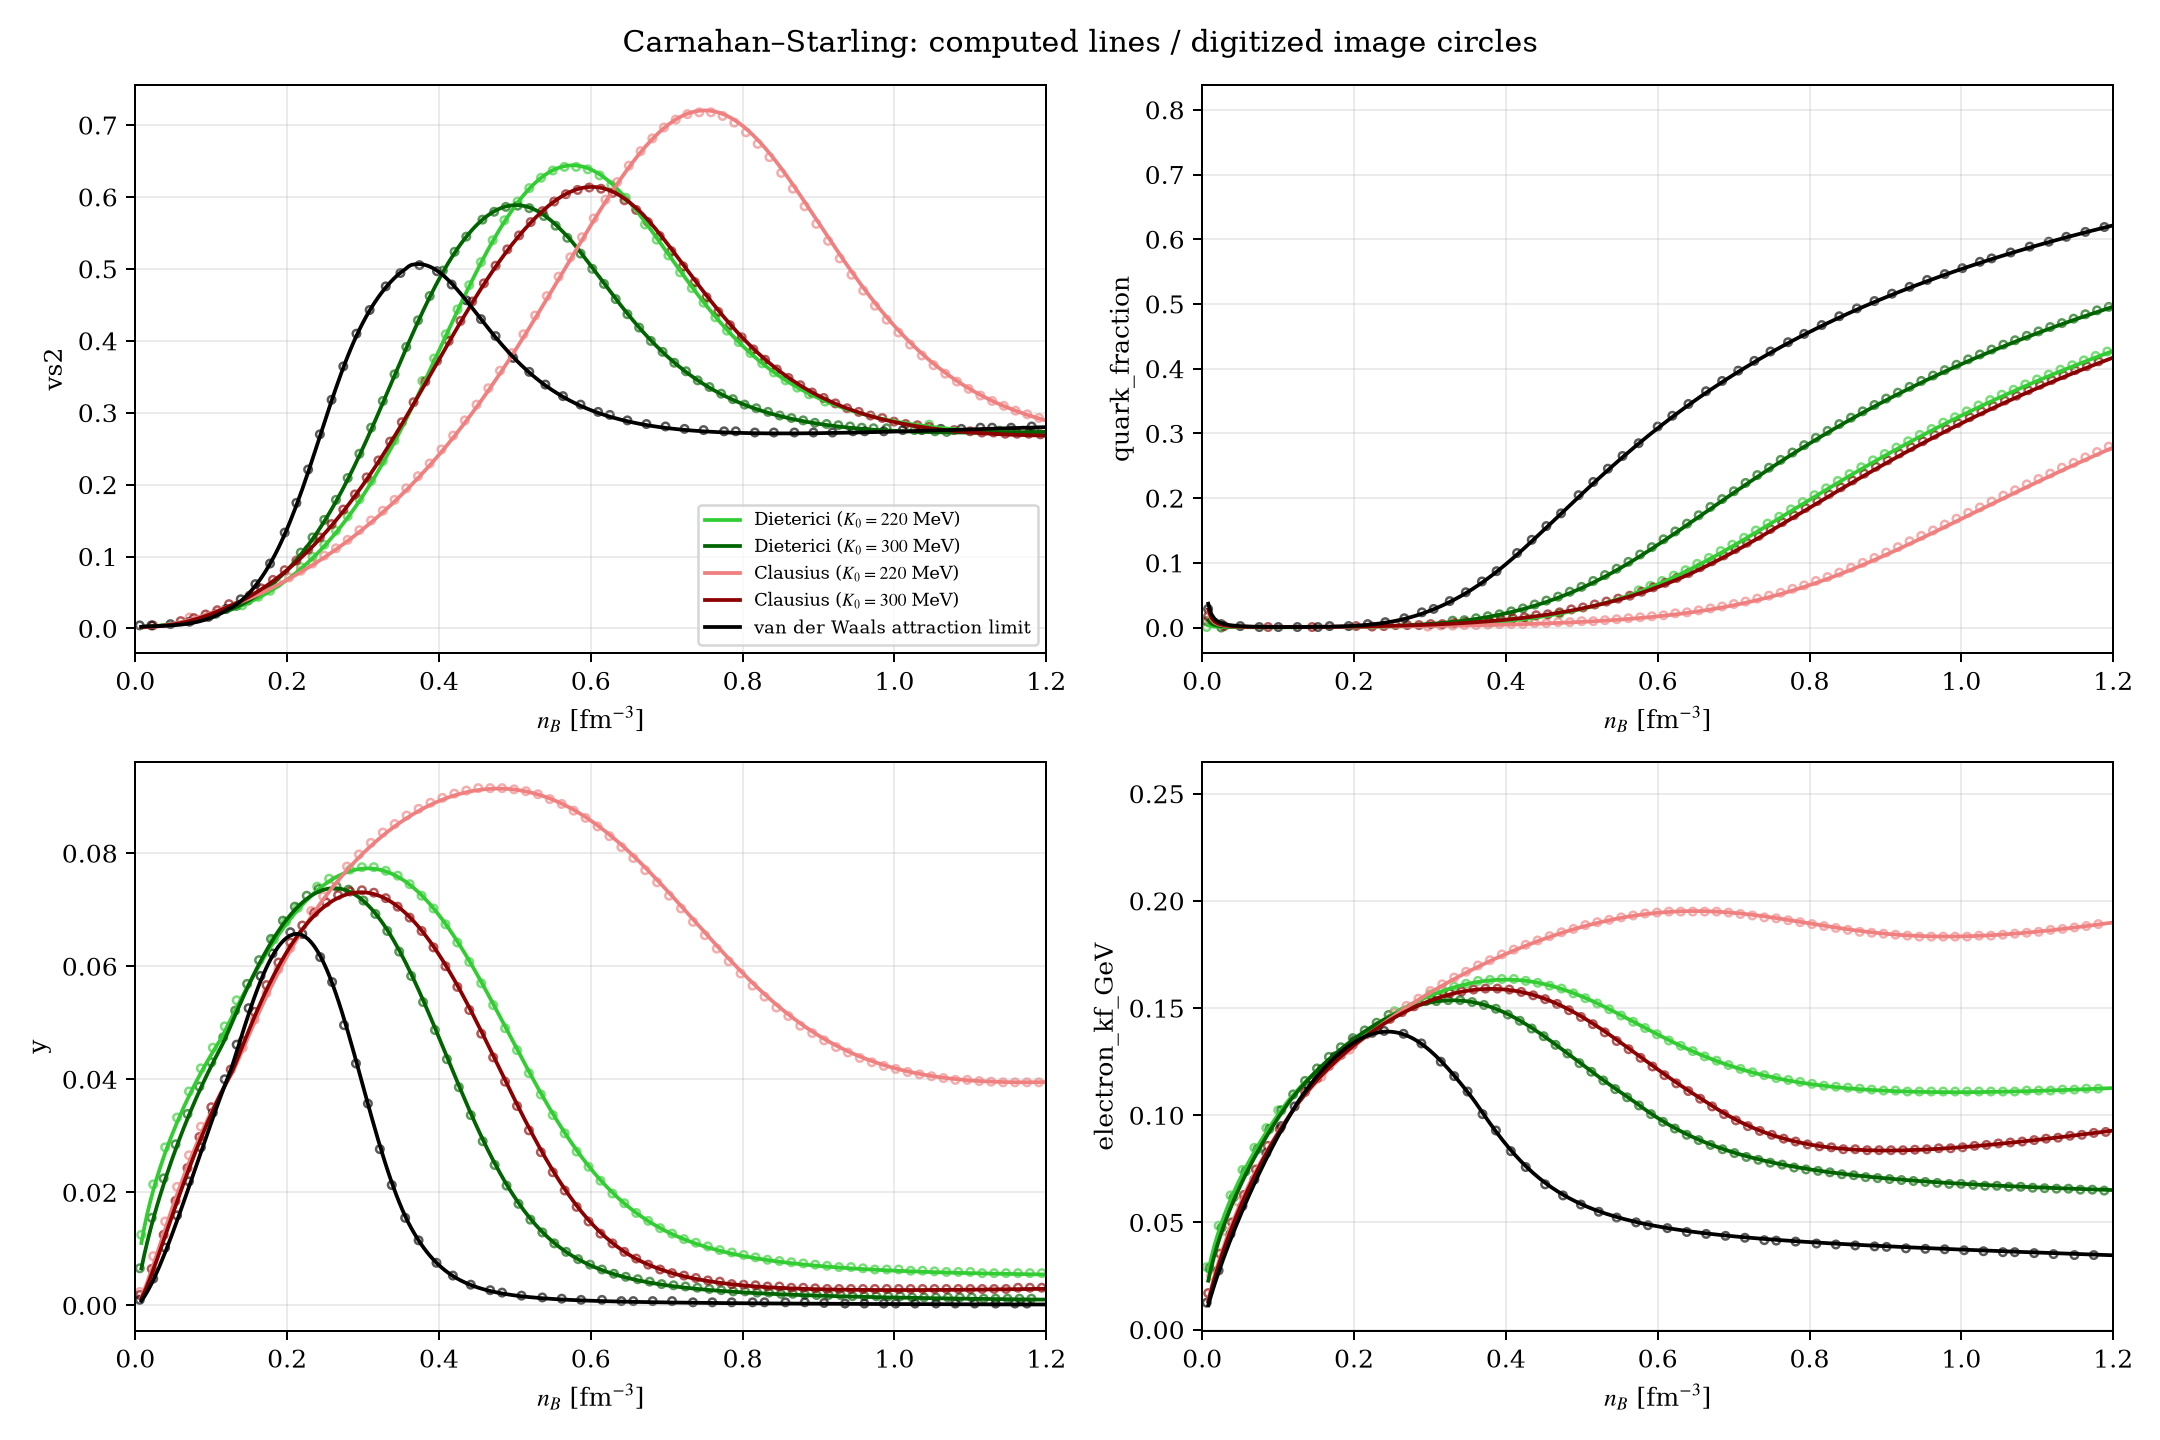

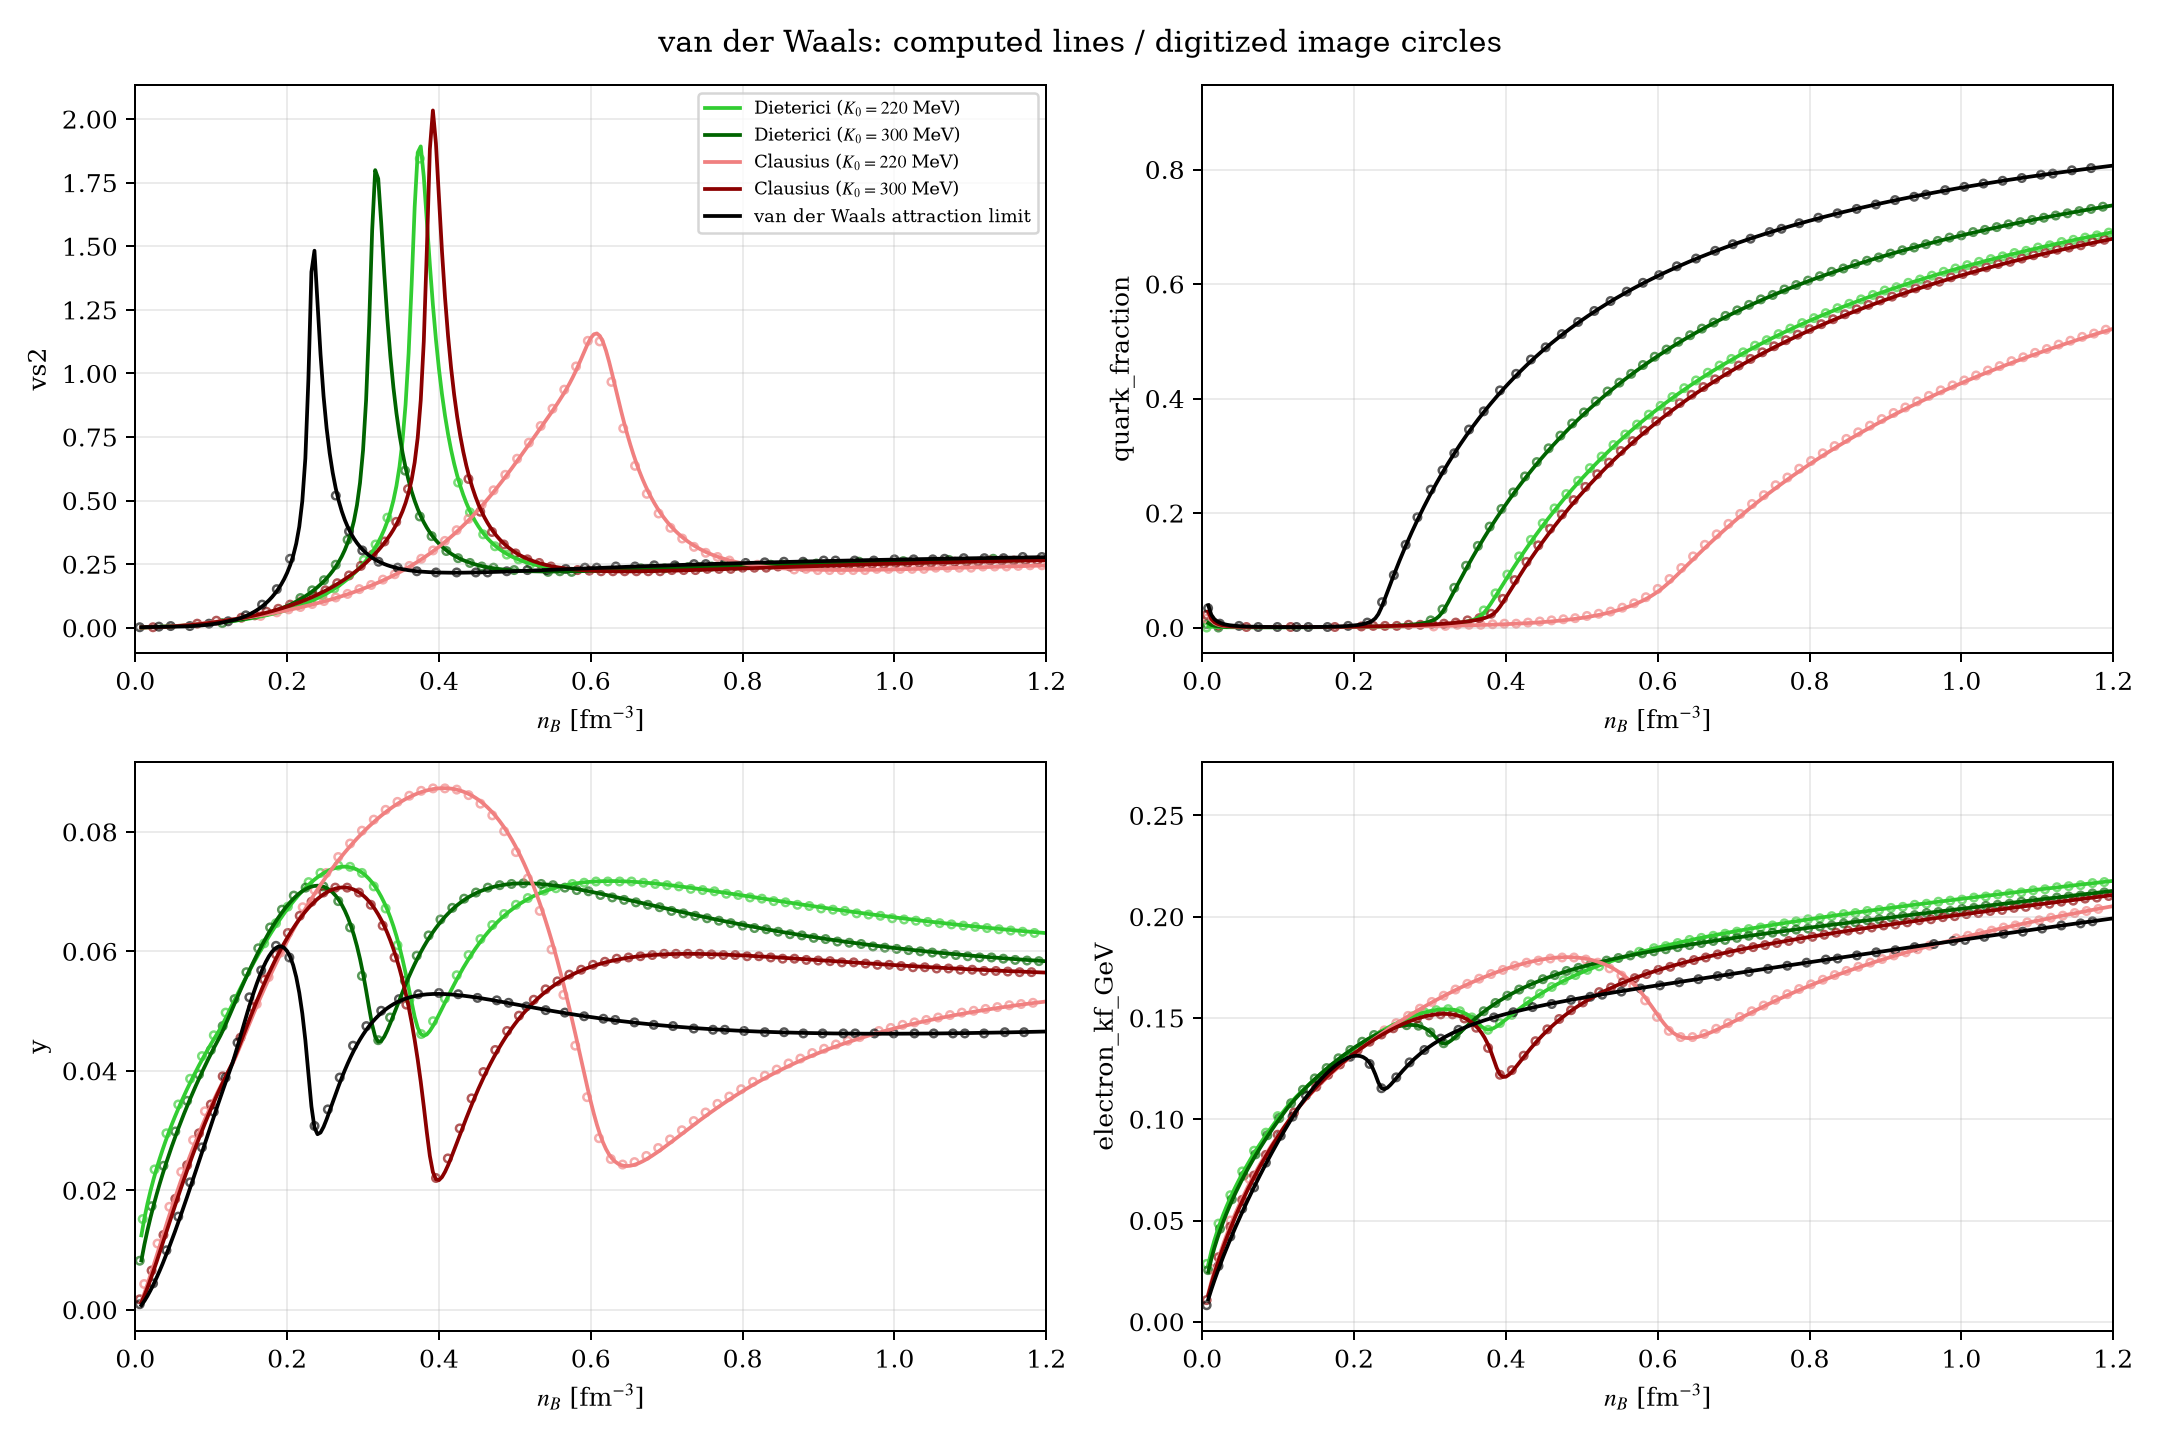

# Audit and reproduction of the incompressibility paper figures

Completed using the files in the **main paper folder**, on 2026-11-11. `old_stuff/` was not used. The calculations use `good_repo/QMM`, not the other QMM copy in the workspace.

The large discrepancies had identifiable causes. The corrected calculation closely follows the supplied composition and sound-speed images. These are recomputed model results, not image tracings presented as calculations. Exact numerical identity cannot be certified without the original numerical tables and full numerical settings.

## Run the notebook

Open `notebooks/03_six_models_paper/paper_replication_lambda300_audited.ipynb` in the QMM Python environment and **Run All**. The historical `screenshot_excluded_volume_comparison.ipynb` now points to this replacement. It retains its old calculations for provenance.

The notebook and `scripts/reproduce_incompressibility_paper.py` use the same implementation. From the QMM directory:

```sh
.venv/bin/python scripts/reproduce_incompressibility_paper.py
```

For a fresh installation: `python -m pip install -e '.[notebook]'`. The default output is `results/generated/paper_replication_lambda300`. Compatible density and stellar checkpoints are reused. Different physical/numerical controls or source hashes select different run directories. `active_runs.json` identifies the final 15 runs; intermediate diagnostic runs remain with their own inputs and source hashes. Any verified checkpoint imports have an explicit `checkpoint_import.json` record.

## 1. Nuclear calibration: the old notebook used the wrong branch

The manuscript states n₀ = 0.16 fm⁻³, binding = −16 MeV, J = 32.5 MeV, L = 58.9 MeV, and K₀ = 220 or 300 MeV. The old notebook assumed `equal_b`: it imposed bpn = bn and **predicted** L. This was not the paper's stated five-constraint calibration. The replacement defaults to `target_l`. Λ is explicitly **300 MeV** in every run; mN = 938 MeV matches the repository and the preceding published model.

`parameters.csv` records the actual fitted couplings and residuals. The vdW-attraction reference has no extra parameter to tune K₀; its K₀ is predicted separately for each excluded-volume family.

## 2. Dieterici: the manuscript body and the original code have different composition dependence

The body of `main_revised.tex` defines

$$v_i^D=-\sum_j a_{ij}\frac{n_j^{\alpha-1}}{\alpha-1}.$$

Consequently, for hadronic species densities np, nn,

$$\epsilon_{\mathrm{att}}^D=-\frac{a_n(n_p^\alpha+n_n^\alpha)+a_{pn}(n_p n_n^{\alpha-1}+n_n n_p^{\alpha-1})}{\alpha-1}.$$

The old QMM implementation instead used

$$-a_{\mathrm{eff}}(Y)\frac{n_H^\alpha}{\alpha-1},\qquad a_{\mathrm{eff}}=a_n[Y^2+(1-Y)^2]+2a_{pn}Y(1-Y).$$

These are different at intermediate Y when α ≠ 2. In particular, they give different beta-equilibrium charge fractions even when the usual calibration checks pass. The appendix repeats the quadratic-coefficient construction and therefore conflicts with the manuscript body. **The supplied PNGs agree with the species-power form in the body.**

To retain exactly the same symmetric and pure-neutron calibration, the paper implementation uses

$$\bar a_{\mathrm{paper}}=2^{\alpha-2}\bar a_{\mathrm{old}},\quad a_{n,\mathrm{paper}}=a_{n,\mathrm{old}},\quad a_{pn,\mathrm{paper}}=2\bar a_{\mathrm{paper}}-a_n.$$

The b couplings and α stay unchanged. The symmetric- and pure-neutron energies then agree at **every** density, preserving binding, K₀, J = EPNM − ESNM, and L. This explains why the old form could pass saturation/J/L checks while still disagreeing with the composition figures. The exported parameter table contains the converted couplings. `dieterici_attraction='qmm'` is available for an explicitly labeled sensitivity comparison.

For example, TVM + Dieterici at K₀ = 300 MeV gives, at nB = 1.2 fm⁻³, approximately **fQ = 0.4682, Y = 0.01967, kFe = 0.1565 GeV**, consistent with the supplied figure.

## 3. The dashed reference is an attraction limit, with the same EV family

The old notebook repeated one **vdW excluded-volume** reference in every row. The paper instead uses **vdW mean-field attraction**, combined with TVM, CS, or vdW excluded volume in the corresponding figure. The new calculation therefore has **15 runs**: four tunable models and one separate reference for each of three excluded-volume families.

## 4. Charge, beta equilibrium, and shell construction

In the exported EOS, nu and nd are **quark number densities**, including color degeneracy. The conserved charges are

$$n_B=n_p+n_n+(n_u+n_d)/3,$$
$$\rho_Q=n_p+(2n_u-n_d)/3=Yn_B=n_e+n_\mu.$$

The manuscript sometimes writes nu and nd as **baryon-normalized** quark contributions. In that convention the equivalent charge is np + 2nuᴮ − ndᴮ. Those conventions must not be mixed. The current original QMM `charge_density_hq` already has the correct factors for its number-density functions; no additional factor of three was introduced here.

The beta condition is

$$\mu_e=\mu_\mu=-\frac{1}{n_B}\left(\frac{\partial\epsilon_{HQ}}{\partial Y}\right)_{n_B,f_Q}.$$

This derivative includes the Y dependence of the common inner shell momentum, both species-dependent volume fractions, and the interaction. Lepton states vanish below their mass thresholds. Total energy, including both leptons, is minimized over fQ. The new evaluator scans for beta roots and competing quark-fraction minima before refinement, instead of assuming one whole-interval golden-section search establishes a global minimum. It scans the physical fraction interval without the original conservative constant lower bound that could discard allowed unequal-b states.

The regulated quark density and energy integrals are evaluated analytically. They agree with adaptive quadrature and the original high-resolution Simpson evaluation. The total-density QMM functional remains available; the manuscript-specific Dieterici correction is explicit in `qmm/paper_reproduction.py`. A separate fix in `quarkyonic.py` makes the pure-quark Dieterici endpoint finite: the vanishing hadronic interaction must not be evaluated as U(0), which was undefined in the original code.

## 5. Pressure and sound speed: the formula is correct, with total equilibrium energy

Use total energy density, including rest mass and leptons, after re-equilibrating composition at each density:

$$\mu_B=\frac{d\epsilon_{\mathrm{eq}}}{dn_B},\quad P=n_B\mu_B-\epsilon_{\mathrm{eq}},\quad c_s^2=\frac{n_B\epsilon_{\mathrm{eq}}''}{\epsilon_{\mathrm{eq}}'}.$$

The original `numpy.gradient` identity is correct. The large discrepancies were primarily the model/calibration choices above. The replacement retains an independent direct-gradient column and uses an **interpolating cubic spline with no smoothing** for its primary derivatives. It solves a grid twice as dense near each peak to measure resolution error. No negative or superluminal values are clipped.

The text's description of μB as the derivative of **strong-sector energy along the equilibrium path** needs correction. Along that path, the charge fraction changes and the lepton derivative contributes. The derivative of total neutral equilibrium energy gives μB. Equivalently, the strong-sector partial derivative for μB holds electric charge fixed. Differentiating only strong-sector energy along the beta path is not the same operation.

## 6. Crust, TOV, and tides

The bundled BPS crust is joined at the highest pressure crossing with the uniform core. The core is required to be strictly increasing and positive above 0.04 fm⁻³; this workflow does not silently delete unstable core samples. The EOS extends to 2.4 fm⁻³ for stellar centers. All 15 sequences have their maximum inside the sampled range. The full sequence, including the descending mass branch, is retained and flagged in `stable_branch`.

Three smaller errors were corrected in the shared `TOVsolver/tov.py`:

- The old solver inferred the surface from a mass plateau after a discontinuous RHS stop, which could produce LSODA failures and uninitialized post-surface rows. The surface is now the interpolated pressure crossing at the tabulated minimum; trial RHS values continue smoothly beyond it and are excluded from the returned star.
- The initial enclosed mass is 4πr³ρ/3; the original expression omitted the division by three.
- The old tidal dρ/dP stencil sampled pressures ±1.5% away from the current pressure and left the EOS table near its boundaries. It now differentiates the same interpolating EOS analytically. Radial fields use monotone interpolation, with boundary values held during LSODA trial stages beyond the requested last radius.

Tidal failures are recorded rather than silently connected in a plot. **All retained points in the final 15 tidal sequences succeeded.** **The final TOV sequences also have zero integration warnings.** Each `tov_meta.json` and `tov_warning_audit.csv` records this. `legacy_tov_warning_audit.csv` preserves the evidence that led to the surface correction. The original observational shaded bands are not recreated because their source contour data are unavailable.

## 7. Measured agreement with the main-folder PNGs

`scripts/compare_paper_pngs.py` digitizes the original colored curves with explicit tick/pixel calibrations, excludes legends, and compares only nB = 0.1–1.18 fm⁻³. The image data never influence model parameters or computed states. Figures named `*_reference_overlay.png` show computed lines and digitized image circles. Curve overlap, antialiasing and the 1400×600 pixel resolution limit the comparison.

The following are **mean per-curve RMSEs**, comparing the same reference pixels before and after the corrections. Electron momenta are in GeV; the other quantities are dimensionless.

| Observable | Old mean curve RMSE | Corrected mean curve RMSE |
| --- | --- | --- |
| vs2 | 0.120606 | 0.0041439 |
| quark_fraction | 0.106605 | 0.0023876 |
| y | 0.0774506 | 0.0003779 |
| electron_kf_GeV | 0.0710079 | 0.000343245 |

The sharp vdW sound-speed peaks are the largest remaining image discrepancy. They are especially sensitive to sampling and numerical differentiation. The model still produces the superluminal peaks visible in the reference; this is a property of that EV choice, not something corrected by clipping.

## 8. Validation and numerical limits

- **26 automated tests pass**, including adaptive quadrature comparisons, analytic versus finite-difference beta derivatives, conservation and muon thresholds, preservation of the Dieterici SNM/PNM calibration, independent two-variable neutral-energy minimization, the CS close-packing regression, analytic sound-speed checks, and tidal derivative/integration checks.
- Across the final tables, maximum charge closure error is **2.31×10⁻¹² fm⁻³** and baryon closure error is **2.00×10⁻¹⁵ fm⁻³**. The independent fourth-order beta residual is below **1.91×10⁻⁴ MeV**; most models are below 3×10⁻⁶ MeV. The larger CS residual occurs near very small Y where energy differencing is ill-conditioned.
- Independent denser minimization scans (fQ scan 61 → 121, Y scan 25 → 81) at four densities for all 15 models changed energy by at most **5.78×10⁻¹¹ MeV fm⁻³**, Y by **5.41×10⁻⁸**, and fQ by **3.01×10⁻⁸**. These are sampled convergence checks, not a mathematical proof that no unsampled minimum exists anywhere.
- Halving the density step from 0.004 to 0.002 fm⁻³ near each sound-speed maximum changes peak height by less than **0.009% for TVM/CS**, and by at most **0.914% for vdW**. Full refinement results are in `peak_refinement.csv` and `peak_convergence.json` in each active run.
- Three representative stellar checks near 1.4 M☉, reducing dr from 500 to 250 cm and tightening ODE tolerance, changed mass by at most **0.0019%**, radius by **0.0198%**, k₂ by **0.0965%**, and tidal Λ by **0.0120%**. See `stellar_convergence.csv`.

The final peak and stellar results are:

| Model | K₀ [MeV] | Fine peak cₛ² | Peak nB [fm⁻³] | Mmax [M☉] |
| --- | --- | --- | --- | --- |
| dieterici_tvm | 220 | 0.625255 | 0.606 | 2.2127 |
| dieterici_tvm | 300 | 0.576614 | 0.524 | 2.2903 |
| clausius_tvm | 220 | 0.692782 | 0.786 | 2.0633 |
| clausius_tvm | 300 | 0.597631 | 0.618 | 2.2081 |
| reference_tvm | reference | 0.498127 | 0.392 | 2.4187 |
| dieterici_cs | 220 | 0.644002 | 0.576 | 2.2553 |
| dieterici_cs | 300 | 0.588667 | 0.502 | 2.3301 |
| clausius_cs | 220 | 0.720355 | 0.750 | 2.0960 |
| clausius_cs | 300 | 0.613995 | 0.602 | 2.2378 |
| reference_cs | reference | 0.506671 | 0.372 | 2.4628 |
| dieterici_vdw | 220 | 1.892544 | 0.374 | 2.6309 |
| dieterici_vdw | 300 | 1.796884 | 0.318 | 2.7192 |
| clausius_vdw | 220 | 1.156440 | 0.608 | 2.3191 |
| clausius_vdw | 300 | 2.015422 | 0.392 | 2.5836 |
| reference_vdw | reference | 1.475000 | 0.234 | 2.8304 |

`parameters.csv`, `validation_summary.csv`, `minimization_convergence.csv`, `stellar_convergence.csv`, `reference_errors.csv` and `legacy_comparison.csv` contain the numerical details. Per-run EOS tables include composition, both derivative estimates, and residuals. Stars and tides use that same stitched EOS.

## 9. Manuscript corrections to make before publication

1. Reconcile the Dieterici interaction in the body with the appendix. The supplied figures favor the species-power expression; document its coupling normalization explicitly.
2. Define whether each nu, nd is a quark number density or a baryon-normalized contribution, and use the corresponding factors consistently.
3. The infrared density-of-states multiplier should be sqrt(q²+Λ²)/q for a radial integrand q sqrt(q²+Λ²). The printed multiplier with q² in its denominator conflicts with that integrand. Integrals already written with a radial q² or k² factor should use dq or dk after angular integration; writing d³q or d³k as well double counts the momentum measure.
4. Clarify that the attractive interaction uses **hadronic** density nH = np + nn. The symbol nB in the real-gas subsection should not be interpreted as including deconfined quarks in that denominator.
5. State that the figure calibration enforces L = 58.9 MeV with unequal b couplings; equal-b results are a different calibration branch.
6. Correct the chemical-potential derivative discussion as described above. `main.tex` also has a negative sign in its stated symmetry-energy target; `main_revised.tex` correctly uses +32.5 MeV.

The previous asymmetric-quarkyonic paper provides an independent primary-source check on the conserved-charge and beta-equilibrium conventions: [Moss, Poberezhniuk and Vovchenko, arXiv:2411.11996, Sec. V](https://arxiv.org/html/2411.11996v1#S5). The specific Dieterici extension here follows your supplied manuscript and is checked against your PNGs.


,model,K0_MeV,observable,old_RMSE,corrected_RMSE
0,dieterici_tvm,220.0,vs2,0.124983,0.002202
1,dieterici_tvm,220.0,quark_fraction,0.141997,0.002601
2,dieterici_tvm,220.0,y,0.120486,0.000249
3,dieterici_tvm,220.0,electron_kf_GeV,0.093275,0.000244
4,dieterici_tvm,300.0,vs2,0.119974,0.002017
5,dieterici_tvm,300.0,quark_fraction,0.155894,0.002419
6,dieterici_tvm,300.0,y,0.107198,0.000284
7,dieterici_tvm,300.0,electron_kf_GeV,0.086802,0.000244
8,clausius_tvm,220.0,vs2,0.089365,0.004269
9,clausius_tvm,220.0,quark_fraction,0.048080,0.002667


,model,K0_MeV,points,max_charge_residual_fm3,max_baryon_residual_fm3,max_beta_residual_fd_mev,minimum_vs2,maximum_vs2,coarse_density_step_fm3,fine_density_step_fm3,coarse_peak_cs2,coarse_peak_density_fm3,fine_peak_cs2,fine_peak_density_fm3,peak_relative_change,fine_peak_at_scan_edge,maximum_mass_msun,radius_at_maximum_mass_km,radius_at_1p4_msun_km,maximum_at_eos_boundary,crust_transition_energy_mev_fm3,crust_transition_pressure_mev_fm3,removed_above_crust_rows,warnings,failed_tides
0,dieterici_tvm,220.0,367,2.131854e-13,8.881784e-16,7.496657e-07,0.001214,0.625245,0.004,0.002,0.625245,0.604,0.625255,0.606,1.612059e-05,False,2.212742,11.344994,12.164990,False,74.535875,0.398374,0,[],0
1,dieterici_tvm,300.0,367,2.040260e-13,1.332268e-15,1.832996e-06,0.001504,0.576631,0.004,0.002,0.576631,0.524,0.576614,0.524,2.980138e-05,False,2.290347,11.943739,12.582259,False,84.532476,0.491947,0,[],0
2,clausius_tvm,220.0,367,9.773085e-14,1.332268e-15,2.965997e-06,0.001464,0.692769,0.004,0.002,0.692769,0.788,0.692782,0.786,1.848042e-05,False,2.063346,10.494942,11.818022,False,70.721184,0.365204,0,[],0
3,clausius_tvm,300.0,367,1.459492e-13,1.332268e-15,1.355306e-06,0.001757,0.597641,0.004,0.002,0.597641,0.620,0.597631,0.618,1.534935e-05,False,2.208146,11.469868,12.478731,False,79.950051,0.447877,0,[],0
4,reference_tvm,NaN,367,1.619330e-13,1.332268e-15,2.378420e-06,0.002269,0.498150,0.004,0.002,0.498150,0.392,0.498127,0.392,4.586989e-05,False,2.418654,13.049834,13.325187,False,104.579242,0.708829,0,[],0
5,dieterici_cs,220.0,367,6.617408e-13,1.776357e-15,8.520216e-07,0.001198,0.644021,0.004,0.002,0.644021,0.576,0.644002,0.576,2.995259e-05,False,2.255291,11.519110,12.212732,False,73.699162,0.390976,0,[],0
6,dieterici_cs,300.0,367,1.622470e-12,1.332268e-15,1.901974e-04,0.001472,0.588667,0.004,0.002,0.588667,0.500,0.588667,0.502,5.280428e-08,False,2.330125,12.079956,12.632207,False,83.136871,0.478317,0,[],0
7,clausius_cs,220.0,367,1.171806e-13,8.881784e-16,1.392817e-06,0.001459,0.720341,0.004,0.002,0.720341,0.752,0.720355,0.750,1.968728e-05,False,2.095996,10.616133,11.833538,False,70.606534,0.364229,0,[],0
8,clausius_cs,300.0,367,2.658594e-13,1.332268e-15,9.193700e-07,0.001743,0.613992,0.004,0.002,0.613992,0.600,0.613995,0.602,4.643869e-06,False,2.237800,11.559771,12.504825,False,79.477142,0.443441,0,[],0
9,reference_cs,NaN,367,2.308257e-12,1.776357e-15,4.424884e-05,0.002268,0.506713,0.004,0.002,0.506713,0.372,0.506671,0.372,8.181569e-05,False,2.462789,13.279672,13.429263,False,104.716939,0.710444,0,[],0


In [8]:
import compare_paper_pngs as ref
reference_errors=ref.compare(jobs,PAPER,OUT)
display(reference_errors)
for ev in rep.EVS:
    display(Image(filename=str(OUT/f'{ev}_reference_overlay.png')))
audit=OUT/'AUDIT.md'
if audit.exists(): display(Markdown(audit.read_text()))
for name in ('legacy_comparison.csv','validation_summary.csv'):
    path=OUT/name
    if path.exists():
        print(name);display(pd.read_csv(path))
